# 🧬 Biohub 132 | Clean Short-Track Rescue + Light Local CV | No Hack

## Clean baseline 0.908 → recover only high-confidence five-node tracks

Kaggle has addressed the historical metric exploit, so **0.908 is treated as the legitimate clean baseline**. Biohub 132 targets a real model weakness: valid short trajectories may be removed by the global minimum-track-length filter.

This notebook keeps the attached baseline pipeline intact and enables a deliberately conservative adaptive rescue. Only existing components of length five are eligible, and they must have high learned-edge confidence and short mean physical displacement. No nodes or edges are fabricated.

**No hack:** no artificial hubs, fake forks, negative-time nodes, out-of-volume coordinates, cross-clip edges, or hidden-test labels.


> **Attach exactly these inputs before running:**
> 1. `Biohub - Cell Tracking During Development`
> 2. `pilkwang/biohub-tracking-support-pack-50ep-v1`
>
> The clean hidden-test `submission.csv` is written and validated first. The fixed-8 CV then runs under a guard and cannot overwrite the submission file.


## Controlled experiment

This is a clean post-processing A/B test from the legitimate `0.908` baseline.

| Setting | 0.908 baseline | Biohub 132 |
|---|---:|---:|
| Motion relaxed gate | `9.5 µm` | `9.5 µm` |
| Minimum retained track length | `6` | `6` |
| Adaptive rescue | disabled | **enabled** |
| Eligible rescued length | none | **exactly 5 nodes** |
| Minimum mean learned-edge probability | n/a | **`0.90`** |
| Maximum mean edge distance | n/a | **`2.75 µm`** |
| Rescue budget | n/a | **min(`0.6%` of nodes, `60`)** |

**Hypothesis:** fixed-8 CV retains meaningful node-recall and edge-FN headroom. A small set of highly coherent five-node components may be genuine trajectories incorrectly removed by the length-six cutoff.


## Pipeline overview

1. **3D detector** proposes candidate cell centers in each frame.
2. **Learned edge scorer** estimates which cells in adjacent frames should be linked.
3. **ILP graph builder** chooses a globally consistent set of detections and links.
4. **Post-processing** repairs short gaps, removes weak isolated fragments, smooths trajectories, and adds only geometrically safe divisions.
5. **Schema validation and diagnostics** check that the final `submission.csv` has valid rows, IDs, and graph statistics.

The main lesson behind this notebook is that cell-tracking competitions are graph problems. A small change to graph construction can matter as much as a detector threshold change.


## Selected settings

| Setting | Value |
|---|---:|
| Clean leaderboard baseline | `0.908` |
| Detection threshold | `0.96875` |
| ILP appearance/disappearance cost | `0.0 / 1.575` |
| Motion tight/relaxed gate | `6.0 / 9.5 µm` |
| Minimum track length | `6` |
| Adaptive short-track rescue | **enabled** |
| Rescue eligible length | **`5` only** |
| Minimum mean edge probability | **`0.90`** |
| Maximum mean edge distance | **`2.75 µm`** |
| Maximum rescued nodes | **`60` or `0.6%`** |
| Safe-division parent/sister radii | `4.66 / 8.5 µm` |


In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
import os

BIOHUB_PRESET = 'biohub_132_clean_short_track_rescue_lightcv_nohack'
BIOHUB_SCORE_AXIS = (
    'Clean recall test: conservatively rescue high-confidence '
    'five-node track components from the legitimate 0.908 baseline'
)
print('Preset:', BIOHUB_PRESET)

Preset: biohub_132_clean_short_track_rescue_lightcv_nohack


### 1. Detection

The UNet outputs a per-voxel center-probability map. Detections are extracted as
local maxima via max-pool (kernel ≈ 3 µm/axis) and kept only when
`sigmoid(logit) > DET_THRESHOLD`.

The GT is **sparse** (not every cell is annotated), so the detector learns to
predict high confidence only for clearly-visible cells. 0.96875 keeps precision
high at the cost of missing faint / occluded cells.

In [4]:
os.environ['BIOHUB_DET_THRESHOLD'] = '0.96875'  # default 0.99; slightly relaxed here

### 2. ILP solver — appearance / disappearance costs

The ILP (`tracksdata.ILPSolver`) picks a globally flow-consistent subset of
candidate edges. Each track must *appear* (birth) and *disappear* (death);
those events carry costs:

- **appearance = 0.0** — tracks may start for free. No penalty for new tracks
  appearing mid-sequence (e.g. cells entering the field of view).
- **disappearance = 1.575** — tracks are penalised for ending early. High value
  pushes the solver to keep linking cells across frames rather than terminating
  a track and re-starting it.

In [5]:
os.environ['BIOHUB_ILP_APPEARANCE_WEIGHT']    = '0.0'    # default 0.1 — free track births
os.environ['BIOHUB_ILP_DISAPPEARANCE_WEIGHT'] = '1.575'  # default 0.1 — penalise early endings

### 3. Motion relinking

After ILP, a motion-based pass re-examines broken links using velocity
extrapolation from the last few confirmed nodes:

- **tight gate (6.0 µm)** — if the extrapolated position is within 6 µm of a
  candidate, the link is accepted unconditionally.
- **relaxed gate (9.5 µm)** — within 9.5 µm the link is accepted only if the
  learned-edge score is above a threshold (weighted by `LEARNED_BONUS`).
- **learned bonus (1.0)** — weight given to the softmax edge probability when
  deciding whether to accept a relaxed-gate candidate.

In [6]:
os.environ['BIOHUB_MOTION_RELINK_TIGHT_UM']      = '6.0'   # accept unconditionally inside this radius
os.environ['BIOHUB_MOTION_RELINK_RELAXED_UM']    = '9.5'   # accept with learned-score check inside this radius
os.environ['BIOHUB_MOTION_RELINK_LEARNED_BONUS'] = '1.0'   # weight on softmax edge prob in the relaxed zone

### 4. Gap closing

Bridges tracks across missing detections (cells that the detector missed
in one frame but correctly detected on either side).

The standard pass closes **1-frame** gaps only (`effective max = min(MAX_GAP, 1)`).
Two-frame gaps (`GAP2_RECOVERY`) are disabled here to avoid loose edges.

**Density-adaptive mode** adjusts the gap-closing radius by local cell density:
in crowded regions the algorithm shrinks the search window to reduce false merges;
in sparse regions it expands it. The `GAIN` controls sensitivity and
`MAX_STEP_DELTA_UM` caps how much each step may change the radius.

In [7]:
os.environ['BIOHUB_GAP_CLOSE_MAX_GAP']           = '2'     # effective max is min(2,1)=1 — standard closer only
os.environ['BIOHUB_GAP_CLOSE_UM']                = '5.8'   # max µm displacement for a gap link
os.environ['BIOHUB_GAP_DENSITY_ADAPTIVE']        = '1'     # enable density-adaptive radius shrink/expand
os.environ['BIOHUB_GAP_DENSITY_REFERENCE_UM']    = '6.5'   # baseline search radius for density adaptation
os.environ['BIOHUB_GAP_DENSITY_GAIN']            = '0.040' # radius change per unit density increase
os.environ['BIOHUB_GAP_DENSITY_MAX_STEP_DELTA_UM'] = '0.125' # per-step cap on density-driven radius change
os.environ['BIOHUB_GAP_DENSITY_NEIGHBORS']       = '3'     # neighbours used to estimate local density
os.environ['BIOHUB_OUTPUT_GAP2_RECOVERY']        = '0'     # two-frame gap recovery disabled

### 5. Short-track filtering

Tracks shorter than `MIN_TRACK_LEN` nodes are dropped after ILP+relinking.
This removes noise fragments (spurious detections with a handful of links)
that would add false TP nodes and FP edges.

`KEEP_DIVISION_COMPONENTS = 1` exempts connected components that contain
a division node — even if the component is short, it may be a genuine mitotic
event and is preserved.

In [8]:
os.environ['BIOHUB_OUTPUT_FILTER_SHORT_TRACKS']      = '1'  # enable the length filter
os.environ['BIOHUB_OUTPUT_MIN_TRACK_LEN']            = '6'  # drop tracks with < 6 nodes
os.environ['BIOHUB_OUTPUT_KEEP_DIVISION_COMPONENTS'] = '1'  # exempt components containing a division

### 6. Safe division insertion

After the main graph is built, a geometry pass looks for potential mitosis events
that the ILP missed and adds them if they pass strict spatial checks:

- **parent radius (4.66 µm)** — the candidate parent cell must be within 4.66 µm
  of the split point.
- **sister radius (8.5 µm)** — the two daughter cells must be within 8.5 µm of
  each other (ensures they're actually siblings).
- **existing-child radius (7.65 µm)** — any pre-existing child must be within
  7.65 µm (prevents false merges).
- **rate caps** — at most 0.76% of nodes per frame and 0.375% of all nodes
  can be division parents, limiting runaway division insertion.

In [9]:
os.environ['BIOHUB_SAFE_DIV_MAX_UM']               = '4.66'   # parent-to-split-point radius
os.environ['BIOHUB_SAFE_DIV_SISTER_MAX_UM']        = '8.5'    # max µm between the two daughters
os.environ['BIOHUB_SAFE_DIV_EXISTING_CHILD_MAX_UM'] = '7.65'  # max µm to existing children
os.environ['BIOHUB_SAFE_DIV_FRAME_FRAC_CAP']       = '0.0076' # max fraction of frame nodes as division parents
os.environ['BIOHUB_SAFE_DIV_GLOBAL_FRAC_CAP']      = '0.00375' # max fraction of all nodes as division parents

### 7. Short-track rescue (this experiment)

**This is the change versus the 0.908 baseline.** The length filter removes
5-node tracks alongside noisy 1-4-node fragments. Some of those 5-node
components are genuine short trajectories (e.g. cells near the edge of the
field of view). The rescue re-admits them under tight quality gates:

| Gate | Value | Meaning |
|---|---|---|
| `MIN_LEN` | 5 | Only exactly-5-node components are eligible |
| `MIN_MEAN_EDGE_PROB` | 0.90 | Mean softmax edge probability across the track must be ≥ 0.90 |
| `MAX_MEAN_EDGE_DIST_UM` | 2.75 µm | Mean physical displacement per step must be ≤ 2.75 µm |
| `MAX_NODES_FRAC` | 0.006 | At most 0.6% of total nodes can be rescued |
| `MAX_NODES_ABS` | 60 | Hard cap of 60 rescued nodes per video |
| `TRIGGER_REMOVED_FRAC` | 0.10 | Rescue only activates if ≥ 10% of nodes were removed |

No new nodes or edges are fabricated — only existing predicted components
that survived the ILP but were dropped by the length filter are considered.

In [10]:
os.environ['BIOHUB_ADAPTIVE_SHORT_TRACK_RESCUE']             = '1'    # enable (off in baseline)
os.environ['BIOHUB_SHORT_TRACK_RESCUE_TRIGGER_REMOVED_FRAC'] = '0.10' # activate only if ≥10% nodes removed
os.environ['BIOHUB_SHORT_TRACK_RESCUE_MIN_LEN']              = '5'    # eligible length: exactly 5 nodes
os.environ['BIOHUB_SHORT_TRACK_RESCUE_MIN_MEAN_EDGE_PROB']   = '0.90' # min mean learned-edge probability
os.environ['BIOHUB_SHORT_TRACK_RESCUE_MAX_MEAN_EDGE_DIST_UM'] = '2.75' # max mean displacement per step
os.environ['BIOHUB_SHORT_TRACK_RESCUE_MAX_NODES_FRAC']       = '0.006' # budget: ≤ 0.6% of total nodes
os.environ['BIOHUB_SHORT_TRACK_RESCUE_MAX_NODES_ABS']        = '60'   # hard cap: 60 rescued nodes per video

### 8. Auxiliary branches (disabled for this run)

**DeepCenter** is a second, independently-trained UNet that scores candidate
positions in the raw image to *veto* potentially spurious gap links and division
insertions added by the post-processing passes. It acts as a gating model:
a gap link proposed by the gap-closer is only kept if DeepCenter also assigns
a high probability to the interpolated centroid position.

It is disabled here to keep the experiment focused on the short-track rescue
change alone. Re-enabling it (`USE_DEEPCENTER_VETO=1`) adds the veto signal
from `biohub-deepcenter-unet3d-center-prior-v1/weights/full_frame_center/checkpoint_last.pt`.

In [11]:
# DeepCenter veto disabled — keeps experiment scope narrow
os.environ['BIOHUB_USE_DEEPCENTER_VETO']              = '0'
os.environ['BIOHUB_REQUIRE_DEEPCENTER_VETO']          = '0'
os.environ['BIOHUB_DEEPCENTER_EXPECTED_EPOCH']        = '0'
os.environ['BIOHUB_DEEPCENTER_CHECKPOINT']            = ''
os.environ['BIOHUB_DEEPCENTER_GAP_VETO']              = '0'
os.environ['BIOHUB_DEEPCENTER_GAP_THRESHOLD']         = '0.20'
os.environ['BIOHUB_DEEPCENTER_GAP_CONFIRM_MIN_SPAN_UM'] = '8.0'
os.environ['BIOHUB_DEEPCENTER_SAFE_DIV_VETO']         = '0'

# Diagnostic output
os.environ['BIOHUB_RUN_VISUAL_EDA']         = '0'
os.environ['BIOHUB_RUN_OUTPUT_DIAGNOSTICS'] = '1'

print('BIOHUB_PRESET:', BIOHUB_PRESET)
print('BIOHUB_SCORE_AXIS:', BIOHUB_SCORE_AXIS)

BIOHUB_PRESET: biohub_132_clean_short_track_rescue_lightcv_nohack
BIOHUB_SCORE_AXIS: Clean recall test: conservatively rescue high-confidence five-node track components from the legitimate 0.908 baseline


In [12]:
from __future__ import annotations

import csv
import importlib.util
import json
import math
import os
import shutil
import subprocess
import tempfile
import zipfile
import sys
import time
from pathlib import Path

import pandas as pd

COMPETITION = "biohub-cell-tracking-during-development"
# Resolved to absolute paths: the prediction subprocess below runs with
# cwd=REPO_DIR (one level deeper than this notebook), so a relative data dir
# would point somewhere else inside the child process.
COMP_DIR = Path("../../../input/").resolve()
TEST_DIR = COMP_DIR / "test"

WORKING_DIR = Path(".").resolve()
REPO_DIR = WORKING_DIR / "tracking_repo"
SUBMISSION_PATH = WORKING_DIR / "submission.csv"
RUN_STATS_PATH = WORKING_DIR / "run_stats.csv"

# Physical voxel size (Z, Y, X) in microns.
VOXEL_SCALE_UM = (1.625, 0.40625, 0.40625)

METHOD = "unet_transformer"
WEIGHTS_RELATIVE = f"weights/{METHOD}/split_0/edge_predictor_best.pth"

EXPERIMENT_TAG = "biohub_132_clean_short_track_rescue_lightcv_nohack"
TARGET_ARTIFACT_SLUG = os.environ.get("BIOHUB_TARGET_ARTIFACT_SLUG", "biohub-tracking-support-pack-50ep-v1")
PRIMARY_ARTIFACT_MANIFEST = Path(os.environ.get(
    "BIOHUB_PRIMARY_ARTIFACT_MANIFEST",
    "../input/biohub-tracking-support-pack-50ep-v1/ARTIFACT_MANIFEST.json",
))
ALLOW_ARTIFACT_FALLBACK = os.environ.get("BIOHUB_ALLOW_ARTIFACT_FALLBACK", "0") != "0"

DET_THRESHOLD = float(os.environ.get("BIOHUB_DET_THRESHOLD", "0.99"))
UNET_BATCH_SIZE = int(os.environ.get("BIOHUB_UNET_BATCH_SIZE", "4"))
USE_ILP = os.environ.get("BIOHUB_USE_ILP", "1") != "0"
ILP_EDGE_WEIGHT = float(os.environ.get("BIOHUB_ILP_EDGE_WEIGHT", "-1.0"))
ILP_APPEARANCE_WEIGHT = float(os.environ.get("BIOHUB_ILP_APPEARANCE_WEIGHT", "0.1"))
ILP_DISAPPEARANCE_WEIGHT = float(os.environ.get("BIOHUB_ILP_DISAPPEARANCE_WEIGHT", "0.1"))
ILP_DIVISION_WEIGHT = float(os.environ.get("BIOHUB_ILP_DIVISION_WEIGHT", "1.0"))

# Empty for a real submission. Useful for local smoke tests, e.g. BIOHUB_SLICE=:1.
SLICE = os.environ.get("BIOHUB_SLICE", "").strip()

# If dependencies are not already installed and no offline wheels are attached,
# this controls whether the notebook attempts PyPI installation.
ALLOW_PIP_INSTALL = os.environ.get("BIOHUB_ALLOW_PIP_INSTALL", "0") != "0"
RUN_OUTPUT_DIAGNOSTICS = os.environ.get("BIOHUB_RUN_OUTPUT_DIAGNOSTICS", "1") != "0"
RUN_VISUAL_EDA = os.environ.get("BIOHUB_RUN_VISUAL_EDA", "1") != "0"

# Output-level graph post-processing.
OUTPUT_EDGE_MAX_UM = float(os.environ.get("BIOHUB_OUTPUT_EDGE_MAX_UM", "14.0"))
OUTPUT_ENFORCE_NEXT_FRAME = os.environ.get("BIOHUB_OUTPUT_ENFORCE_NEXT_FRAME", "1") != "0"
OUTPUT_SINGLE_PARENT_REPAIR = os.environ.get("BIOHUB_OUTPUT_SINGLE_PARENT_REPAIR", "1") != "0"
OUTPUT_SINGLE_CHILD_REPAIR = os.environ.get("BIOHUB_OUTPUT_SINGLE_CHILD_REPAIR", "0") != "0"
OUTPUT_PRUNE_ISOLATED = os.environ.get("BIOHUB_OUTPUT_PRUNE_ISOLATED", "1") != "0"
OUTPUT_MOTION_RELINK = os.environ.get("BIOHUB_OUTPUT_MOTION_RELINK", "1") != "0"
MOTION_RELINK_TIGHT_UM = float(os.environ.get("BIOHUB_MOTION_RELINK_TIGHT_UM", "6.0"))
MOTION_RELINK_RELAXED_UM = float(os.environ.get("BIOHUB_MOTION_RELINK_RELAXED_UM", "10.0"))
MOTION_RELINK_VELOCITY_WEIGHT = float(os.environ.get("BIOHUB_MOTION_RELINK_VELOCITY_WEIGHT", "0.5"))
MOTION_RELINK_LEARNED_BONUS = float(os.environ.get("BIOHUB_MOTION_RELINK_LEARNED_BONUS", "0.75"))
MOTION_RELINK_MAX_FRAME_NODES = int(os.environ.get("BIOHUB_MOTION_RELINK_MAX_FRAME_NODES", "2600"))

OUTPUT_DIVISION_GEOMETRY_FILTER = os.environ.get("BIOHUB_OUTPUT_DIVISION_GEOMETRY_FILTER", "0") != "0"
DIV_PARENT_MAX_UM = float(os.environ.get("BIOHUB_DIV_PARENT_MAX_UM", "10.5"))
DIV_SISTER_MAX_UM = float(os.environ.get("BIOHUB_DIV_SISTER_MAX_UM", "8.0"))
DIV_DROP_TO_SINGLE_IF_BAD = os.environ.get("BIOHUB_DIV_DROP_TO_SINGLE_IF_BAD", "1") != "0"
OUTPUT_GAP_CLOSE = os.environ.get("BIOHUB_OUTPUT_GAP_CLOSE", "1") != "0"
GAP_CLOSE_MAX_GAP = int(os.environ.get("BIOHUB_GAP_CLOSE_MAX_GAP", "1"))
GAP_CLOSE_UM = float(os.environ.get("BIOHUB_GAP_CLOSE_UM", "6.0"))
GAP_DENSITY_ADAPTIVE = os.environ.get("BIOHUB_GAP_DENSITY_ADAPTIVE", "0") != "0"
GAP_DENSITY_REFERENCE_UM = float(os.environ.get("BIOHUB_GAP_DENSITY_REFERENCE_UM", "6.5"))
GAP_DENSITY_GAIN = float(os.environ.get("BIOHUB_GAP_DENSITY_GAIN", "0.040"))
GAP_DENSITY_MAX_STEP_DELTA_UM = float(os.environ.get("BIOHUB_GAP_DENSITY_MAX_STEP_DELTA_UM", "0.125"))
GAP_DENSITY_NEIGHBORS = int(os.environ.get("BIOHUB_GAP_DENSITY_NEIGHBORS", "3"))
GAP_CLOSE_REUSE_EXISTING = os.environ.get("BIOHUB_GAP_CLOSE_REUSE_EXISTING", "1") != "0"
GAP_CLOSE_REUSE_UM = float(os.environ.get("BIOHUB_GAP_CLOSE_REUSE_UM", "3.2"))
GAP_CLOSE_MAX_ADDED_FRAC = float(os.environ.get("BIOHUB_GAP_CLOSE_MAX_ADDED_FRAC", "0.05"))
GAP_CLOSE_MAX_ADDED_ABS = int(os.environ.get("BIOHUB_GAP_CLOSE_MAX_ADDED_ABS", "2000"))
GAP_REFINE_SYNTHETIC = os.environ.get("BIOHUB_GAP_REFINE_SYNTHETIC", "1") != "0"
GAP_REFINE_WIN_Z = int(os.environ.get("BIOHUB_GAP_REFINE_WIN_Z", "1"))
GAP_REFINE_WIN_YX = int(os.environ.get("BIOHUB_GAP_REFINE_WIN_YX", "3"))
GAP_REFINE_MAX_SHIFT_UM = float(os.environ.get("BIOHUB_GAP_REFINE_MAX_SHIFT_UM", "3.2"))

OUTPUT_FILTER_SHORT_TRACKS = os.environ.get("BIOHUB_OUTPUT_FILTER_SHORT_TRACKS", "1") != "0"
OUTPUT_MIN_TRACK_LEN = int(os.environ.get("BIOHUB_OUTPUT_MIN_TRACK_LEN", "6"))
OUTPUT_KEEP_DIVISION_COMPONENTS = os.environ.get("BIOHUB_OUTPUT_KEEP_DIVISION_COMPONENTS", "1") != "0"
ADAPTIVE_SHORT_TRACK_RESCUE = os.environ.get("BIOHUB_ADAPTIVE_SHORT_TRACK_RESCUE", "0") != "0"
SHORT_TRACK_RESCUE_TRIGGER_REMOVED_FRAC = float(os.environ.get("BIOHUB_SHORT_TRACK_RESCUE_TRIGGER_REMOVED_FRAC", "0.10"))
SHORT_TRACK_RESCUE_MIN_LEN = int(os.environ.get("BIOHUB_SHORT_TRACK_RESCUE_MIN_LEN", "4"))
SHORT_TRACK_RESCUE_MIN_MEAN_EDGE_PROB = float(os.environ.get("BIOHUB_SHORT_TRACK_RESCUE_MIN_MEAN_EDGE_PROB", "0.82"))
SHORT_TRACK_RESCUE_MAX_MEAN_EDGE_DIST_UM = float(os.environ.get("BIOHUB_SHORT_TRACK_RESCUE_MAX_MEAN_EDGE_DIST_UM", "3.25"))
SHORT_TRACK_RESCUE_MAX_NODES_FRAC = float(os.environ.get("BIOHUB_SHORT_TRACK_RESCUE_MAX_NODES_FRAC", "0.018"))
SHORT_TRACK_RESCUE_MAX_NODES_ABS = int(os.environ.get("BIOHUB_SHORT_TRACK_RESCUE_MAX_NODES_ABS", "180"))

OUTPUT_LINEFIT_SMOOTH = os.environ.get("BIOHUB_OUTPUT_LINEFIT_SMOOTH", "1") != "0"
OUTPUT_LINEFIT_WEIGHT = float(os.environ.get("BIOHUB_OUTPUT_LINEFIT_WEIGHT", "0.8"))
OUTPUT_LINEFIT_WINDOW = int(os.environ.get("BIOHUB_OUTPUT_LINEFIT_WINDOW", "2"))

OUTPUT_GAP2_RECOVERY = os.environ.get("BIOHUB_OUTPUT_GAP2_RECOVERY", "0") != "0"
GAP2_MAX_TOTAL_UM = float(os.environ.get("BIOHUB_GAP2_MAX_TOTAL_UM", "10.2"))
GAP2_MAX_STEP_UM = float(os.environ.get("BIOHUB_GAP2_MAX_STEP_UM", "4.4"))
GAP2_MAX_LINKS_FRAC = float(os.environ.get("BIOHUB_GAP2_MAX_LINKS_FRAC", "0.0045"))
GAP2_MAX_LINKS_ABS = int(os.environ.get("BIOHUB_GAP2_MAX_LINKS_ABS", "180"))
GAP2_REQUIRE_CONTEXT = os.environ.get("BIOHUB_GAP2_REQUIRE_CONTEXT", "1") != "0"
GAP2_FRAME_FRAC_CAP = float(os.environ.get("BIOHUB_GAP2_FRAME_FRAC_CAP", "0.006"))

OUTPUT_SAFE_DIVISIONS = os.environ.get("BIOHUB_OUTPUT_SAFE_DIVISIONS", "1") != "0"
SAFE_DIV_MAX_UM = float(os.environ.get("BIOHUB_SAFE_DIV_MAX_UM", "4.7"))
SAFE_DIV_SISTER_MAX_UM = float(os.environ.get("BIOHUB_SAFE_DIV_SISTER_MAX_UM", "7.2"))
SAFE_DIV_EXISTING_CHILD_MAX_UM = float(os.environ.get("BIOHUB_SAFE_DIV_EXISTING_CHILD_MAX_UM", "7.8"))
SAFE_DIV_FRAME_FRAC_CAP = float(os.environ.get("BIOHUB_SAFE_DIV_FRAME_FRAC_CAP", "0.008"))
SAFE_DIV_GLOBAL_FRAC_CAP = float(os.environ.get("BIOHUB_SAFE_DIV_GLOBAL_FRAC_CAP", "0.004"))

# DeepCenter support is retained for compatibility, but this selected run keeps it disabled.
USE_DEEPCENTER_VETO = os.environ.get("BIOHUB_USE_DEEPCENTER_VETO", "1") != "0"
REQUIRE_DEEPCENTER_VETO = os.environ.get("BIOHUB_REQUIRE_DEEPCENTER_VETO", "1") != "0"
DEEPCENTER_MANIFEST_DEFAULT = os.environ.get(
    "BIOHUB_DEEPCENTER_MANIFEST_DEFAULT",
    "../input/biohub-deepcenter-unet3d-center-prior-v1/ARTIFACT_MANIFEST.json",
)
DEEPCENTER_CHECKPOINT_DEFAULT = os.environ.get(
    "BIOHUB_DEEPCENTER_CHECKPOINT_DEFAULT",
    "../input/input/biohub-deepcenter-unet3d-center-prior-v1/weights/full_frame_center/checkpoint_last.pt",
)
DEEPCENTER_RELATIVE = os.environ.get("BIOHUB_DEEPCENTER_RELATIVE", "weights/full_frame_center/checkpoint_last.pt")
DEEPCENTER_GAP_VETO = os.environ.get("BIOHUB_DEEPCENTER_GAP_VETO", "1") != "0"
DEEPCENTER_SAFE_DIV_VETO = os.environ.get("BIOHUB_DEEPCENTER_SAFE_DIV_VETO", "1") != "0"
DEEPCENTER_GAP_THRESHOLD = float(os.environ.get("BIOHUB_DEEPCENTER_GAP_THRESHOLD", "0.10"))
DEEPCENTER_EXPECTED_EPOCH = int(os.environ.get("BIOHUB_DEEPCENTER_EXPECTED_EPOCH", "0"))
DEEPCENTER_GAP_CONFIRM_MIN_SPAN_UM = float(os.environ.get("BIOHUB_DEEPCENTER_GAP_CONFIRM_MIN_SPAN_UM", "0"))
DEEPCENTER_SAFE_DIV_THRESHOLD = float(os.environ.get("BIOHUB_DEEPCENTER_SAFE_DIV_THRESHOLD", "0.12"))
DEEPCENTER_SCORE_WIN_Z = int(os.environ.get("BIOHUB_DEEPCENTER_SCORE_WIN_Z", "1"))
DEEPCENTER_SCORE_WIN_YX = int(os.environ.get("BIOHUB_DEEPCENTER_SCORE_WIN_YX", "2"))
DEEPCENTER_SCORE_CACHE_MAX_FRAMES = int(os.environ.get("BIOHUB_DEEPCENTER_SCORE_CACHE_MAX_FRAMES", "8"))

CONFIG_DISPLAY = {
    "experiment_tag": EXPERIMENT_TAG,
    "method": METHOD,
    "weights": WEIGHTS_RELATIVE,
    "target_artifact_slug": TARGET_ARTIFACT_SLUG,
    "primary_artifact_manifest": str(PRIMARY_ARTIFACT_MANIFEST),
    "allow_artifact_fallback": ALLOW_ARTIFACT_FALLBACK,
    "det_threshold": DET_THRESHOLD,
    "unet_batch_size": UNET_BATCH_SIZE,
    "use_ilp": USE_ILP,
    "ilp_edge_weight": ILP_EDGE_WEIGHT,
    "ilp_appearance_weight": ILP_APPEARANCE_WEIGHT,
    "ilp_disappearance_weight": ILP_DISAPPEARANCE_WEIGHT,
    "ilp_division_weight": ILP_DIVISION_WEIGHT,
    "slice": SLICE,
    "allow_pip_install": ALLOW_PIP_INSTALL,
    "run_visual_eda": RUN_VISUAL_EDA,
    "output_edge_max_um": OUTPUT_EDGE_MAX_UM,
    "output_enforce_next_frame": OUTPUT_ENFORCE_NEXT_FRAME,
    "output_single_parent_repair": OUTPUT_SINGLE_PARENT_REPAIR,
    "output_single_child_repair": OUTPUT_SINGLE_CHILD_REPAIR,
    "output_prune_isolated": OUTPUT_PRUNE_ISOLATED,
    "output_motion_relink": OUTPUT_MOTION_RELINK,
    "motion_relink_tight_um": MOTION_RELINK_TIGHT_UM,
    "motion_relink_relaxed_um": MOTION_RELINK_RELAXED_UM,
    "motion_relink_velocity_weight": MOTION_RELINK_VELOCITY_WEIGHT,
    "motion_relink_learned_bonus": MOTION_RELINK_LEARNED_BONUS,
    "motion_relink_max_frame_nodes": MOTION_RELINK_MAX_FRAME_NODES,
    "output_division_geometry_filter": OUTPUT_DIVISION_GEOMETRY_FILTER,
    "div_parent_max_um": DIV_PARENT_MAX_UM,
    "div_sister_max_um": DIV_SISTER_MAX_UM,
    "div_drop_to_single_if_bad": DIV_DROP_TO_SINGLE_IF_BAD,
    "output_gap_close": OUTPUT_GAP_CLOSE,
    "gap_close_max_gap": GAP_CLOSE_MAX_GAP,
    "gap_close_effective_max_gap": min(GAP_CLOSE_MAX_GAP, 1),
    "gap_close_um": GAP_CLOSE_UM,
    "gap_density_adaptive": GAP_DENSITY_ADAPTIVE,
    "gap_density_reference_um": GAP_DENSITY_REFERENCE_UM,
    "gap_density_gain": GAP_DENSITY_GAIN,
    "gap_density_max_step_delta_um": GAP_DENSITY_MAX_STEP_DELTA_UM,
    "gap_density_neighbors": GAP_DENSITY_NEIGHBORS,
    "gap_close_reuse_existing": GAP_CLOSE_REUSE_EXISTING,
    "gap_close_reuse_um": GAP_CLOSE_REUSE_UM,
    "gap_close_max_added_frac": GAP_CLOSE_MAX_ADDED_FRAC,
    "gap_close_max_added_abs": GAP_CLOSE_MAX_ADDED_ABS,
    "gap_refine_synthetic": GAP_REFINE_SYNTHETIC,
    "gap_refine_win_z": GAP_REFINE_WIN_Z,
    "gap_refine_win_yx": GAP_REFINE_WIN_YX,
    "gap_refine_max_shift_um": GAP_REFINE_MAX_SHIFT_UM,
    "output_filter_short_tracks": OUTPUT_FILTER_SHORT_TRACKS,
    "output_min_track_len": OUTPUT_MIN_TRACK_LEN,
    "output_keep_division_components": OUTPUT_KEEP_DIVISION_COMPONENTS,
    "adaptive_short_track_rescue": ADAPTIVE_SHORT_TRACK_RESCUE,
    "short_track_rescue_trigger_removed_frac": SHORT_TRACK_RESCUE_TRIGGER_REMOVED_FRAC,
    "short_track_rescue_min_len": SHORT_TRACK_RESCUE_MIN_LEN,
    "short_track_rescue_min_mean_edge_prob": SHORT_TRACK_RESCUE_MIN_MEAN_EDGE_PROB,
    "short_track_rescue_max_mean_edge_dist_um": SHORT_TRACK_RESCUE_MAX_MEAN_EDGE_DIST_UM,
    "short_track_rescue_max_nodes_frac": SHORT_TRACK_RESCUE_MAX_NODES_FRAC,
    "short_track_rescue_max_nodes_abs": SHORT_TRACK_RESCUE_MAX_NODES_ABS,
    "output_linefit_smooth": OUTPUT_LINEFIT_SMOOTH,
    "output_linefit_weight": OUTPUT_LINEFIT_WEIGHT,
    "output_linefit_window": OUTPUT_LINEFIT_WINDOW,
    "output_gap2_recovery": OUTPUT_GAP2_RECOVERY,
    "gap2_max_total_um": GAP2_MAX_TOTAL_UM,
    "gap2_max_step_um": GAP2_MAX_STEP_UM,
    "gap2_max_links_frac": GAP2_MAX_LINKS_FRAC,
    "gap2_max_links_abs": GAP2_MAX_LINKS_ABS,
    "gap2_require_context": GAP2_REQUIRE_CONTEXT,
    "gap2_frame_frac_cap": GAP2_FRAME_FRAC_CAP,
    "output_safe_divisions": OUTPUT_SAFE_DIVISIONS,
    "safe_div_max_um": SAFE_DIV_MAX_UM,
    "safe_div_sister_max_um": SAFE_DIV_SISTER_MAX_UM,
    "safe_div_existing_child_max_um": SAFE_DIV_EXISTING_CHILD_MAX_UM,
    "safe_div_frame_frac_cap": SAFE_DIV_FRAME_FRAC_CAP,
    "safe_div_global_frac_cap": SAFE_DIV_GLOBAL_FRAC_CAP,
    "use_deepcenter_add_only_gate": USE_DEEPCENTER_VETO,
    "deepcenter_gap_add_gate": DEEPCENTER_GAP_VETO,
    "deepcenter_safe_div_add_gate": DEEPCENTER_SAFE_DIV_VETO,
    "deepcenter_gap_threshold": DEEPCENTER_GAP_THRESHOLD,
    "deepcenter_expected_epoch": DEEPCENTER_EXPECTED_EPOCH,
    "deepcenter_gap_confirm_min_span_um": DEEPCENTER_GAP_CONFIRM_MIN_SPAN_UM,
    "deepcenter_safe_div_threshold": DEEPCENTER_SAFE_DIV_THRESHOLD,
    "deepcenter_checkpoint_default": DEEPCENTER_CHECKPOINT_DEFAULT,
}

print("Biohub learned UNet + node-transformer + ILP submission")
print("COMP_DIR:", COMP_DIR, "exists:", COMP_DIR.exists())
print("TEST_DIR:", TEST_DIR, "exists:", TEST_DIR.exists())
print(json.dumps(CONFIG_DISPLAY, indent=2, sort_keys=True))

Biohub learned UNet + node-transformer + ILP submission
COMP_DIR: /data/kaggle-cell-tracking/input exists: True
TEST_DIR: /data/kaggle-cell-tracking/input/test exists: True
{
  "adaptive_short_track_rescue": true,
  "allow_artifact_fallback": false,
  "allow_pip_install": false,
  "deepcenter_checkpoint_default": "../input/input/biohub-deepcenter-unet3d-center-prior-v1/weights/full_frame_center/checkpoint_last.pt",
  "deepcenter_expected_epoch": 0,
  "deepcenter_gap_add_gate": false,
  "deepcenter_gap_confirm_min_span_um": 8.0,
  "deepcenter_gap_threshold": 0.2,
  "deepcenter_safe_div_add_gate": false,
  "deepcenter_safe_div_threshold": 0.12,
  "det_threshold": 0.96875,
  "div_drop_to_single_if_bad": true,
  "div_parent_max_um": 10.5,
  "div_sister_max_um": 8.0,
  "experiment_tag": "biohub_132_clean_short_track_rescue_lightcv_nohack",
  "gap2_frame_frac_cap": 0.006,
  "gap2_max_links_abs": 180,
  "gap2_max_links_frac": 0.0045,
  "gap2_max_step_um": 4.4,
  "gap2_max_total_um": 10.2,
  "

## Artifact and Dependency Setup

The notebook expects a compact support artifact containing the inference source,
trained weights, and optionally offline dependency wheels. The primary Kaggle
attachment path is:

```text
/kaggle/input/datasets/pilkwang/biohub-tracking-support-pack-50ep-v1/ARTIFACT_MANIFEST.json
```

The setup cell first uses already-installed modules, then attached wheels, and
only attempts an internet install when explicitly enabled for local development.
By default, the artifact resolver accepts only the 50-epoch package named by
`TARGET_ARTIFACT_SLUG`; set `BIOHUB_ALLOW_ARTIFACT_FALLBACK=1` only for local
debugging against an older package.


In [13]:
from kaggle_setup import (
    find_artifacts_root,
    artifact_manifest,
    ensure_dependencies,
    materialize_inference_repo,
)

ARTIFACTS = find_artifacts_root(METHOD)
print("ARTIFACTS:", ARTIFACTS)
print("Has offline wheels:", (ARTIFACTS / "wheels").exists())
manifest_info = artifact_manifest(ARTIFACTS)
if manifest_info:
    print("Artifact name:", manifest_info.get("artifact_name"))
    print("Weight sha256:", manifest_info.get("model", {}).get("weight_sha256"))
    print("Weight path:", manifest_info.get("model", {}).get("weight_path"))

ensure_dependencies(ARTIFACTS)


ARTIFACTS: ../input/biohub-tracking-support-pack-50ep-v1
Has offline wheels: True
Artifact name: biohub-tracking-support-pack-400ep-snapshot-v1
Weight sha256: 12f6881ee3620a831697ca098ff8f48e687a24225f4e048b538deec3562fe771
Weight path: weights/unet_transformer/split_0/edge_predictor_best.pth
Required graph/Zarr/ILP packages import successfully.


In [14]:
materialize_inference_repo(ARTIFACTS, REPO_DIR, WEIGHTS_RELATIVE)

Inference repo: /data/kaggle-cell-tracking/notebooks/clean-approach-lightweight-local-cv-no-hack/working/tracking_repo
Weights: /data/kaggle-cell-tracking/notebooks/clean-approach-lightweight-local-cv-no-hack/working/tracking_repo/weights/unet_transformer/split_0/edge_predictor_best.pth


## Predict Candidate Graphs

The inference step writes one `.geff` graph per test video. Keeping graph
prediction separate from CSV conversion makes the graph repair and diagnostics
transparent.


### Step 1 — Input guards

Fail fast before any GPU work if the competition data or CUDA is missing.

In [15]:
# Verify competition test data is attached
if not TEST_DIR.exists():
    raise FileNotFoundError(
        "Competition test data is missing at " + str(TEST_DIR) + "\n"
        "Attach Biohub - Cell Tracking During Development with Add Input."
    )

# Verify GPU — inference on CPU would time out on the hidden test set
import torch as _torch_guard
print("torch", _torch_guard.__version__, "cuda", _torch_guard.cuda.is_available(), flush=True)
if not _torch_guard.cuda.is_available():
    raise RuntimeError("CUDA is unavailable. Stop before inference to avoid CPU timeout.")
print("device=cuda", _torch_guard.cuda.get_device_name(0), flush=True)

torch 2.13.0+cu130 cuda True
device=cuda NVIDIA H100 80GB HBM3


### Step 2 — Patch TTA in `predict_unet_transformer.py`

The baseline script uses **4-way TTA** (original + 3 axis flips, averaged).
This patch upgrades it to the full **spatial D4 group** — the 8 symmetries of
a square applied to the XY plane:

| Transform | Code |
|---|---|
| Identity (original) | implicit |
| Flip X | `imgs.flip(-1)` |
| Flip Y | `imgs.flip(-2)` |
| Flip XY | `imgs.flip(-2, -1)` |
| Rotate 90° | `torch.rot90(imgs, 1, dims=(-2,-1))` |
| Rotate 270° | `torch.rot90(imgs, 3, dims=(-2,-1))` |
| Transpose | `imgs.transpose(-1, -2)` |
| Anti-transpose | `rot90 then transpose` |

Z is intentionally excluded: the data is highly anisotropic (Z ≈ 4× coarser
than XY), so Z-flips would produce out-of-distribution inputs.

The patch edits the source file in-place before the subprocess is launched.
Each augmented prediction is summed into `det_logits` and divided by `_nv` (= 8)
to produce the averaged detection probability map.

In [16]:
_ps = REPO_DIR / "scripts" / "predict_unet_transformer.py"
_s = _ps.read_text()

_old = """        if cfg.det_tta:
            tta_flips = [(-1,), (-2,), (-2, -1)]
            for dims in tta_flips:
                imgs_flip = imgs.flip(dims)
                _, det_flip = model.encode(imgs_flip)
                for f in range(W):
                    det_logits[f] = det_logits[f] + det_flip[f].flip(dims)
                del imgs_flip, det_flip
            for f in range(W):
                det_logits[f] = det_logits[f] / 4"""

_new = """        if cfg.det_tta:
            _nv = 1
            for dims in [(-1,), (-2,), (-2, -1)]:
                imgs_flip = imgs.flip(dims)
                _, det_flip = model.encode(imgs_flip)
                for f in range(W):
                    det_logits[f] = det_logits[f] + det_flip[f].flip(dims)
                del imgs_flip, det_flip
                _nv += 1
            for _k in (1, 3):
                imgs_rot = torch.rot90(imgs, _k, dims=(-2, -1))
                _, det_rot = model.encode(imgs_rot)
                for f in range(W):
                    det_logits[f] = det_logits[f] + torch.rot90(det_rot[f], -_k, dims=(-2, -1))
                del imgs_rot, det_rot
                _nv += 1
            imgs_t = imgs.transpose(-1, -2)
            _, det_t = model.encode(imgs_t)
            for f in range(W):
                det_logits[f] = det_logits[f] + det_t[f].transpose(-1, -2)
            del imgs_t, det_t
            _nv += 1
            imgs_at = torch.rot90(imgs, 1, dims=(-2, -1)).transpose(-1, -2)
            _, det_at = model.encode(imgs_at)
            for f in range(W):
                det_logits[f] = det_logits[f] + torch.rot90(det_at[f].transpose(-1, -2), -1, dims=(-2, -1))
            del imgs_at, det_at
            _nv += 1
            for f in range(W):
                det_logits[f] = det_logits[f] / _nv"""

if _old in _s:
    _ps.write_text(_s.replace(_old, _new))
    print("TTA patch applied: 4-way → D4 (8 transforms)")
else:
    print("TTA WARNING: block not found - using default 4-way")

TTA WARNING: block not found - using default 4-way


### Step 3 — Discover test videos

Scans `TEST_DIR` for `.zarr` folders. Each is one video clip; the stem
(`{embryo_id}_{field_of_view}`) becomes the `dataset` column in `submission.csv`.

A lightweight JSON splits file is written so `predict_unet_transformer.py`
knows which videos to run (the script normally reads cross-validation folds;
here we give it a single fold containing all test videos).

In [17]:
def list_test_stems() -> list[str]:
    if not TEST_DIR.exists():
        raise FileNotFoundError(f"Test directory does not exist: {TEST_DIR}")
    stems = sorted(path.name[:-5] for path in TEST_DIR.iterdir() if path.name.endswith(".zarr"))
    if not stems:
        raise FileNotFoundError(f"No test .zarr files found in {TEST_DIR}")
    return stems

test_stems = list_test_stems()
print(f"Found {len(test_stems)} test videos")
print(test_stems[:10])

splits_path = REPO_DIR / "kaggle_test_splits_50ep.json"
splits_path.parent.mkdir(parents=True, exist_ok=True)
splits_path.write_text(json.dumps([{"split": 0, "train": [], "test": test_stems}], indent=2))

Found 4 test videos
['44b6_0113de3b', '44b6_0b24845f', '6bba_05b6850b', '6bba_05db0fb1']


155

### Step 4 — Inference: what happens to one sample

The subprocess runs `predict_unet_transformer.py`, which calls `predict_video()` for
each `.zarr` in the test set. The cells below trace exactly what happens to one sample.

**Sample shape:** `(T=100, Z=64, Y=256, X=256)` uint16  
**Physical scale:** z=1.625 µm, y=x=0.40625 µm/voxel  
**Spatial downsample:** `(dz=1, dy=4, dx=4)` → working grid `(64, 64, 64)`

The prediction script itself lives on disk, not inline in this notebook: see
`tracking_repo/scripts/predict_unet_transformer.py`. The next cell always
runs that on-disk file as a subprocess, so it is the single source of truth
for the prediction pipeline (`load_model`, `predict_video`, `predict`, CLI).


In [19]:
USE_ILP = False

In [20]:
predict_cmd = [
    sys.executable,
    "scripts/predict_unet_transformer.py",
    "--data-dir",         str(TEST_DIR),
    "--splits",           str(splits_path.name),
    "--split",            "0",
    "--weights",          WEIGHTS_RELATIVE,
    "--unet-batch-size",  str(UNET_BATCH_SIZE),
    "--det-threshold",    str(DET_THRESHOLD),
    "--ilp-edge-weight",  str(ILP_EDGE_WEIGHT),
    "--ilp-appearance-weight",    str(ILP_APPEARANCE_WEIGHT),
    "--ilp-disappearance-weight", str(ILP_DISAPPEARANCE_WEIGHT),
    "--ilp-division-weight",      str(ILP_DIVISION_WEIGHT),
]

if USE_ILP:
    predict_cmd.append("--use-ilp")
    
if SLICE:
    predict_cmd.extend(["--slice", SLICE])

start_time = time.time()
print(" ".join(predict_cmd))
subprocess.run(predict_cmd, cwd=REPO_DIR, env={**os.environ, "PYTHONPATH": "src"}, check=True)
predict_seconds = time.time() - start_time
print(f"Prediction completed in {predict_seconds / 60:.2f} minutes")

/data/kaggle-cell-tracking/.venv/bin/python scripts/predict_unet_transformer.py --data-dir /data/kaggle-cell-tracking/input/test --splits kaggle_test_splits_50ep.json --split 0 --weights weights/unet_transformer/split_0/edge_predictor_best.pth --unet-batch-size 4 --det-threshold 0.96875 --ilp-edge-weight -1.0 --ilp-appearance-weight 0.0 --ilp-disappearance-weight 1.575 --ilp-division-weight 1.0
Fold 0: 4 datasets | weights=weights/unet_transformer/split_0/edge_predictor_best.pth | device=cuda | window_size=2 | pool_kernel_um=3.0
Saved 4 predictions to /data/kaggle-cell-tracking/notebooks/clean-approach-lightweight-local-cv-no-hack/working/tracking_repo/predictions/root/unet_transformer/split_0
Prediction completed in 0.92 minutes


## Build `submission.csv`

Rows are streamed directly to disk with the required schema. This avoids holding
the full hidden-test submission table in memory.

The standard gap closer intentionally handles only one missing frame. Two-missing-frame repair is handled by the stricter `gap2` pass so that a loose environment override cannot introduce non-consecutive edges.


In [21]:
from postprocess import (
    PostprocessConfig,
    graph_from_geff,
    load_deepcenter_veto_detector,
    filter_output_graph,
)

SUBMISSION_COLUMNS = ["dataset", "row_type", "node_id", "t", "z", "y", "x", "source_id", "target_id"]
CSV_COLUMNS = ["id", *SUBMISSION_COLUMNS]
POSTPROCESS_CFG = PostprocessConfig.from_notebook_globals(globals())

DEEPCENTER_VETO_DETECTOR = load_deepcenter_veto_detector(POSTPROCESS_CFG)

geffs = sorted((REPO_DIR / "predictions").glob(f"*/{METHOD}/split_0/*.geff"))
print(f"Found {len(geffs)} prediction graphs")
if len(geffs) != len(test_stems):
    found = {path.stem for path in geffs}
    missing = sorted(set(test_stems) - found)
    raise RuntimeError(f"Expected {len(test_stems)} graphs, found {len(geffs)}. Missing: {missing[:10]}")

stats_rows: list[dict[str, object]] = []
seen_datasets: set[str] = set()
row_id = 0
total_nodes = 0
total_edges = 0

with SUBMISSION_PATH.open("w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=CSV_COLUMNS)
    writer.writeheader()

    for geff_path in geffs:
        dataset = geff_path.stem
        seen_datasets.add(dataset)
        graph = graph_from_geff(geff_path)

        nodes_by_id: dict[int, dict[str, object]] = {}
        for row in graph.node_attrs().iter_rows(named=True):
            node_id = int(row["node_id"])
            nodes_by_id[node_id] = {
                "node_id": node_id,
                "t": int(row["t"]),
                "z": float(row["z"]),
                "y": float(row["y"]),
                "x": float(row["x"]),
            }

        raw_edges: list[dict[str, object]] = []
        for row in graph.edge_attrs().iter_rows(named=True):
            edge_prob = row.get("edge_prob") if hasattr(row, "get") else None
            raw_edges.append({
                "source_id": int(row["source_id"]),
                "target_id": int(row["target_id"]),
                "edge_prob": None if edge_prob is None else float(edge_prob),
            })

        raw_node_count = len(nodes_by_id)
        nodes_by_id, edges, filter_stats = filter_output_graph(
            nodes_by_id, raw_edges, POSTPROCESS_CFG, TEST_DIR,
            dataset=dataset, deepcenter_bundle=DEEPCENTER_VETO_DETECTOR,
        )
        if not nodes_by_id:
            raise AssertionError(f"{dataset}: post-processing removed every node")

        for node_id in sorted(nodes_by_id):
            node = nodes_by_id[node_id]
            writer.writerow({
                "id": row_id,
                "dataset": dataset,
                "row_type": "node",
                "node_id": int(node["node_id"]),
                "t": int(node["t"]),
                "z": max(0, int(round(float(node["z"])))),
                "y": max(0, int(round(float(node["y"])))),
                "x": max(0, int(round(float(node["x"])))),
                "source_id": -1,
                "target_id": -1,
            })
            row_id += 1

        division_sources: dict[int, int] = {}
        for edge in edges:
            source_id = int(edge["source_id"])
            target_id = int(edge["target_id"])
            if source_id not in nodes_by_id or target_id not in nodes_by_id:
                raise AssertionError(f"{dataset}: dangling edge after filtering")
            writer.writerow({
                "id": row_id,
                "dataset": dataset,
                "row_type": "edge",
                "node_id": -1,
                "t": -1,
                "z": -1,
                "y": -1,
                "x": -1,
                "source_id": source_id,
                "target_id": target_id,
            })
            row_id += 1
            division_sources[source_id] = division_sources.get(source_id, 0) + 1

        node_count = len(nodes_by_id)
        edge_count = len(edges)
        total_nodes += node_count
        total_edges += edge_count
        stats_rows.append({
            "dataset": dataset,
            "raw_nodes": raw_node_count,
            "nodes": node_count,
            "raw_edges": filter_stats["raw_edges"],
            "edges": edge_count,
            "division_like_sources": sum(1 for count in division_sources.values() if count >= 2),
            "edge_to_node_ratio": edge_count / max(node_count, 1),
            "gap_added_nodes_frac": filter_stats.get("gap_added_nodes", 0) / max(raw_node_count, 1),
            **filter_stats,
        })

expected_datasets = set(test_stems)
missing_datasets = sorted(expected_datasets - seen_datasets)
extra_datasets = sorted(seen_datasets - expected_datasets)
if missing_datasets or extra_datasets:
    raise AssertionError({"missing": missing_datasets[:10], "extra": extra_datasets[:10]})
assert row_id == total_nodes + total_edges, "Internal row counter mismatch"
assert total_nodes > 0, "No node rows produced"

header = SUBMISSION_PATH.open().readline().strip().split(",")
assert header == CSV_COLUMNS, f"Bad CSV header: {header}"

stats = pd.DataFrame(stats_rows).sort_values("dataset").reset_index(drop=True)
stats["predict_minutes_total"] = predict_seconds / 60.0
stats["experiment_tag"] = EXPERIMENT_TAG
stats.to_csv(RUN_STATS_PATH, index=False)

print(f"Wrote {SUBMISSION_PATH} with {row_id:,} rows")
print(f"Node rows: {total_nodes:,} | edge rows: {total_edges:,}")
print(f"Wrote {RUN_STATS_PATH}")
display(stats.describe(include="all"))
display(pd.read_csv(SUBMISSION_PATH, nrows=8))


DeepCenter add-only repair gate disabled by configuration.
Found 4 prediction graphs
Wrote /data/kaggle-cell-tracking/notebooks/clean-approach-lightweight-local-cv-no-hack/working/submission.csv with 265,405 rows
Node rows: 135,276 | edge rows: 130,129
Wrote /data/kaggle-cell-tracking/notebooks/clean-approach-lightweight-local-cv-no-hack/working/run_stats.csv


,dataset,raw_nodes,nodes,raw_edges,edges,division_like_sources,edge_to_node_ratio,gap_added_nodes_frac,dropped_nonconsecutive_edges,dropped_long_edges,...,short_track_filter_skipped_all,short_track_rescue_triggered,short_track_rescue_components,short_track_rescue_nodes,short_track_rescue_budget,linefit_smoothed_nodes,linefit_skipped_nodes,gap_close_effective_max_gap,predict_minutes_total,experiment_tag
count,4,4.00000,4.000000,4.00000,4.000000,4.000000,4.000000,4.000000,4.0,4.000000,...,4.0,4.00,4.00,4.00,4.0,4.000000,4.000000,4.0,4.000000,4
unique,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
top,44b6_0113de3b,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,biohub_132_clean_short_track_rescue_lightcv_no...
freq,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4
mean,NaN,35568.75000,33819.000000,30801.75000,32532.250000,117.000000,0.958200,0.023399,0.0,3.500000,...,0.0,0.25,2.25,11.25,15.0,33801.500000,17.500000,1.0,0.917273,NaN
std,NaN,28767.40312,28876.686733,26447.93932,28100.352707,110.568229,0.017025,0.018693,0.0,3.316625,...,0.0,0.50,4.50,22.50,30.0,28870.206656,10.785793,0.0,0.000000,NaN
min,NaN,7252.00000,6781.000000,6301.00000,6501.000000,26.000000,0.933960,0.006343,0.0,1.000000,...,0.0,0.00,0.00,0.00,0.0,6775.000000,6.000000,1.0,0.917273,NaN
25%,NaN,21440.50000,21056.500000,19292.50000,20411.250000,48.500000,0.952521,0.014524,0.0,1.000000,...,0.0,0.00,0.00,0.00,0.0,21046.750000,9.750000,1.0,0.917273,NaN
50%,NaN,29802.50000,26891.500000,24264.50000,25584.500000,84.000000,0.964276,0.018623,0.0,2.500000,...,0.0,0.00,0.00,0.00,0.0,26871.500000,17.500000,1.0,0.917273,NaN
75%,NaN,43930.75000,39654.000000,35773.75000,37705.500000,152.500000,0.969955,0.027498,0.0,5.000000,...,0.0,0.25,2.25,11.25,15.0,39626.250000,25.250000,1.0,0.917273,NaN


,id,dataset,row_type,node_id,t,z,y,x,source_id,target_id
0,0,44b6_0113de3b,node,0,0,1,10,52,-1,-1
1,1,44b6_0113de3b,node,1,0,1,8,71,-1,-1
2,2,44b6_0113de3b,node,2,0,1,25,64,-1,-1
3,3,44b6_0113de3b,node,3,0,1,51,84,-1,-1
4,4,44b6_0113de3b,node,4,0,1,100,36,-1,-1
5,5,44b6_0113de3b,node,5,0,1,127,72,-1,-1
6,6,44b6_0113de3b,node,6,0,1,163,28,-1,-1
7,7,44b6_0113de3b,node,7,0,1,181,64,-1,-1


## Promotion rule

- Legitimate clean leaderboard baseline: `0.908`.
- This notebook changes only the adaptive short-track rescue branch.
- Promote only when fixed-8 LocalCV improves, node recall or edge TP increases, and FP growth remains controlled.
- Reject the candidate when rescue adds many rows without a positive paired CV delta.


In [22]:
# ＊＊＊＊＊ GPT FEEDBACK START / END ＊＊＊＊＊
import hashlib
from pathlib import Path

_feedback_path = Path(SUBMISSION_PATH)
_feedback_sha = hashlib.sha256(_feedback_path.read_bytes()).hexdigest()
_feedback_rows = int(total_nodes + total_edges)
_feedback_divisions = int(stats["division_like_sources"].sum()) if "division_like_sources" in stats else 0
_feedback_activation = int(
    stats["gap_density_candidates_expanded"].sum()
    + stats["gap_density_candidates_restricted"].sum()
)
_feedback_cols = [
    "dataset", "nodes", "edges", "division_like_sources",
    "gap_candidates", "gap_pairs_selected",
    "gap_density_candidates_expanded", "gap_density_selected_outside_base",
]

# Clean-submission audit. This checks only biological/format validity and does not alter predictions.
_audit_df = pd.read_csv(_feedback_path)
_node_df = _audit_df[_audit_df["row_type"] == "node"].copy()
_edge_df = _audit_df[_audit_df["row_type"] == "edge"].copy()
_clean_audit_rows = []
for _dataset in test_stems:
    _zarr_meta = json.loads((TEST_DIR / f"{_dataset}.zarr" / "0" / "zarr.json").read_text())
    _shape = tuple(int(v) for v in _zarr_meta["shape"])
    _n = _node_df[_node_df["dataset"] == _dataset]
    _e = _edge_df[_edge_df["dataset"] == _dataset]
    _node_times = dict(zip(_n["node_id"].astype(int), _n["t"].astype(int)))
    _valid_ids = set(_node_times)
    _dangling = int(sum((int(s) not in _valid_ids) or (int(t) not in _valid_ids) for s, t in zip(_e["source_id"], _e["target_id"])))
    _nonconsecutive = int(sum(_node_times.get(int(t), -999) != _node_times.get(int(s), -999) + 1 for s, t in zip(_e["source_id"], _e["target_id"])))
    _outdegree = _e.groupby("source_id").size() if len(_e) else pd.Series(dtype=int)
    _max_outdegree = int(_outdegree.max()) if len(_outdegree) else 0
    _bad_time = int(((_n["t"] < 0) | (_n["t"] >= _shape[0])).sum())
    _bad_z = int(((_n["z"] < 0) | (_n["z"] >= _shape[1])).sum())
    _bad_y = int(((_n["y"] < 0) | (_n["y"] >= _shape[2])).sum())
    _bad_x = int(((_n["x"] < 0) | (_n["x"] >= _shape[3])).sum())
    _clean_audit_rows.append({
        "dataset": _dataset,
        "node_time_violations": _bad_time,
        "coordinate_violations": _bad_z + _bad_y + _bad_x,
        "dangling_edges": _dangling,
        "nonconsecutive_edges": _nonconsecutive,
        "max_outdegree": _max_outdegree,
    })
_clean_audit = pd.DataFrame(_clean_audit_rows)
if int(_clean_audit[["node_time_violations", "coordinate_violations", "dangling_edges", "nonconsecutive_edges"]].to_numpy().sum()) != 0:
    raise AssertionError("Clean-submission audit failed:\n" + _clean_audit.to_string(index=False))
if int(_clean_audit["max_outdegree"].max()) > 2:
    raise AssertionError("Unexpected hub-like source detected:\n" + _clean_audit.to_string(index=False))

_REF_124_ROWS, _REF_124_NODES, _REF_124_EDGES, _REF_124_DIVISIONS = 236185, 120210, 115975, 308

print("")
print("＊＊＊＊＊ GPT FEEDBACK START ＊＊＊＊＊")
print("Notebook: biohub_132_clean_short_track_rescue_lightcv_nohack")
print("Public title: 🧬 Biohub 132 | Clean Short-Track Rescue + Light Local CV | No Hack")
print("Legitimate clean leaderboard baseline after metric fix: 0.908")
print("Strategy: rescue only high-confidence five-node components removed by the minimum-length-six filter")
print("Detection threshold: 0.96875")
print("ILP appearance cost: 0.0")
print("ILP disappearance cost: 1.575")
print("Motion relink tight / relaxed gate: 6.0 / 9.5")
print("Adaptive short-track rescue: True")
print("Rescue minimum length: 5")
print("Rescue minimum mean edge probability: 0.90")
print("Rescue maximum mean edge distance: 2.75 µm")
print("Rescue maximum node fraction / absolute cap: 0.006 / 60")
print("Automatic input discovery: False")
print("Artificial hub/fork nodes added: False")
print("Negative-time nodes added: False")
print("Out-of-volume nodes added: False")
print("Cross-clip graph edges added: False")
print("Hidden-test labels used: False")
print("Model inference passes: 1")
print(f"Prediction minutes: {predict_seconds / 60.0:.2f}")
print(f"Rows: {_feedback_rows}")
print(f"Node rows: {int(total_nodes)}")
print(f"Edge rows: {int(total_edges)}")
print(f"Division-like sources: {_feedback_divisions}")
print(f"SHA256: {_feedback_sha}")
print(f"Short-track rescue triggered datasets: {int((stats['short_track_rescue_triggered'] > 0).sum()) if 'short_track_rescue_triggered' in stats else 0}")
print(f"Short-track components rescued: {int(stats['short_track_rescue_components'].sum()) if 'short_track_rescue_components' in stats else 0}")
print(f"Short-track nodes rescued: {int(stats['short_track_rescue_nodes'].sum()) if 'short_track_rescue_nodes' in stats else 0}")
print("Difference versus the historical Notebook-124 clean graph reference:")
print(f"- Rows delta: {_feedback_rows - _REF_124_ROWS:+d}")
print(f"- Node delta: {int(total_nodes) - _REF_124_NODES:+d}")
print(f"- Edge delta: {int(total_edges) - _REF_124_EDGES:+d}")
print(f"- Division-like source delta: {_feedback_divisions - _REF_124_DIVISIONS:+d}")
print("Per-dataset key statistics:")
print(stats[_feedback_cols + ['short_track_rescue_triggered', 'short_track_rescue_components', 'short_track_rescue_nodes']].to_string(index=False))
print("Clean-submission audit:")
print(_clean_audit.to_string(index=False))
print("Submit recommendation: PROMOTE ONLY IF FIXED-8 LITE CV IMPROVES WITH CONTROLLED FP")
print("＊＊＊＊＊ GPT FEEDBACK END ＊＊＊＊＊")


AssertionError: Unexpected hub-like source detected:
      dataset  node_time_violations  coordinate_violations  dangling_edges  nonconsecutive_edges  max_outdegree
44b6_0113de3b                     0                      0               0                     0              2
44b6_0b24845f                     0                      0               0                     0              2
6bba_05b6850b                     0                      0               0                     0              2
6bba_05db0fb1                     0                      0               0                     0              3

In [23]:
COMP_DIR

PosixPath('/data/kaggle-cell-tracking/input')

In [24]:
# FINAL KAGGLE SUBMISSION GUARD
from pathlib import Path
import pandas as pd
_submit_file = Path("./submission.csv")
if not _submit_file.exists():
    raise FileNotFoundError("submission.csv was not created at ./submission.csv")
_submit_check = pd.read_csv(_submit_file, nrows=5)
_expected = ["id", "dataset", "row_type", "node_id", "t", "z", "y", "x", "source_id", "target_id"]
if list(_submit_check.columns) != _expected:
    raise ValueError(f"Unexpected submission columns: {list(_submit_check.columns)}")
print("SUBMISSION_READY: ./submission.csv")
print("Kaggle output filename: submission.csv")


SUBMISSION_READY: ./submission.csv
Kaggle output filename: submission.csv


## Fixed-8 Official-Spec Lite CV

The hidden-test `submission.csv` is written and protected before diagnostics. The fixed public-train split then measures whether rescued five-node components improve node recall and edge TP without adding excessive FP.

Inspect `short_track_rescue_components`, `short_track_rescue_nodes`, edge TP/FP/FN, node recall, and the paired score delta together.


In [25]:

# -----------------------------------------------------------------------------
# Guarded Lite-CV phase. submission.csv already exists and has passed the final
# Kaggle schema guard above. This phase never overwrites that file.
# -----------------------------------------------------------------------------
import traceback

from eval_spec import (
    OFFICIAL_SPEC_REPOSITORY,
    OFFICIAL_SPEC_COMMIT,
    OFFICIAL_SPEC_DOCUMENT,
    OFFICIAL_SPEC_MAX_DISTANCE_UM,
    OFFICIAL_SPEC_EXACT_SOURCE_COPY,
    paired_train_stems,
    resolve_cv_stems,
    official_spec_evaluate,
    official_spec_per_sample,
    official_spec_summarise,
    _graph_tables,
    _estimated_total_nodes,
)

_SUBMISSION_FILE_SAFE = Path('./submission.csv')
_SUBMISSION_SHA_BEFORE_CV = hashlib.sha256(_SUBMISSION_FILE_SAFE.read_bytes()).hexdigest()
_SUBMISSION_ROWS_BEFORE_CV = sum(1 for _ in _SUBMISSION_FILE_SAFE.open('r', encoding='utf-8')) - 1

CV_STATUS_PATH = WORKING_DIR / '127_lite_cv_status.json'
CV_FIXED_DATASETS = [
    '44b6_0113de3b', '44b6_0b24845f', '44b6_341df25f', '44b6_e57ff5c6',
    '6bba_05b6850b', '6bba_05db0fb1', '6bba_969618f6', '6bba_fc83837d',
]

_original_test_dir = TEST_DIR
_original_submission_path = SUBMISSION_PATH
_original_run_stats_path = RUN_STATS_PATH
_original_experiment_tag = EXPERIMENT_TAG

cv_status = {
    'status': 'not_started',
    'datasets': CV_FIXED_DATASETS,
    'submission_sha_before_cv': _SUBMISSION_SHA_BEFORE_CV,
    'submission_rows_before_cv': _SUBMISSION_ROWS_BEFORE_CV,
}

try:
    TRAIN_DIR = COMP_DIR / 'train'
    if not TRAIN_DIR.exists():
        raise FileNotFoundError(f'CV train directory not found: {TRAIN_DIR}')

    TEST_DIR = TRAIN_DIR
    SUBMISSION_PATH = WORKING_DIR / '127_official_spec_smoke_cv_predictions.csv'
    RUN_STATS_PATH = WORKING_DIR / '127_official_spec_smoke_cv_run_stats.csv'
    EXPERIMENT_TAG = '127_combined_offline_smoke_cv'
    CV_DATASETS_OVERRIDE = list(CV_FIXED_DATASETS)
    CV_ALLOW_MIXED_FALLBACK = False
    OFFICIAL_GEFF_DIR = WORKING_DIR / '127_official_spec_smoke_cv_geffs'
    OFFICIAL_METRIC_ROWS_PATH = WORKING_DIR / '127_official_spec_smoke_metric_per_dataset.csv'
    OFFICIAL_METRIC_SUMMARY_PATH = WORKING_DIR / '127_official_spec_smoke_metric_summary.json'
    OFFICIAL_METRIC_STDOUT_PATH = WORKING_DIR / '127_official_spec_smoke_metric_notes.txt'

    # Remove only temporary model prediction graphs. The already-written submission.csv
    # remains untouched in ./.
    shutil.rmtree(REPO_DIR / 'predictions', ignore_errors=True)

    # ------------------------- pre-GPU self-tests -------------------------
    _gt_n = pd.DataFrame([(1,0,0,0,0),(2,1,0,1,0),(3,1,0,-1,0)], columns=["node_id","t","z","y","x"])
    _gt_e = pd.DataFrame([(1,2),(1,3)], columns=["source_id","target_id"])
    _pr_n = _gt_n.copy(); _pr_e = _gt_e.copy()
    _r = official_spec_evaluate(_pr_n, _pr_e, _gt_n, _gt_e)
    assert (_r.edge_tp,_r.edge_fp,_r.edge_fn)==(2,0,0), _r
    assert (_r.division_tp,_r.division_fn)==(1,0), _r
    # An unmatched sentinel fork has no local GT evidence and must never become a TP.
    _hn = pd.DataFrame(
        [(10,-1000,-10000,-10000,-10000),(11,-999,-10000,-10000,-10000),(12,-999,-10001,-10000,-10000)],
        columns=["node_id","t","z","y","x"],
    )
    try:
        official_spec_evaluate(_hn, pd.DataFrame([(10,11),(10,12)], columns=["source_id","target_id"]), _gt_n, _gt_e)
        raise AssertionError("sentinel exploit audit did not fire")
    except ValueError:
        pass

    _SPEC_FINGERPRINT = hashlib.sha256(
        (OFFICIAL_SPEC_REPOSITORY + OFFICIAL_SPEC_COMMIT + OFFICIAL_SPEC_DOCUMENT + "offline-spec-v1").encode()
    ).hexdigest()
    print("OFFLINE OFFICIAL-SPEC PREFLIGHT PASSED — GPU inference may start.")
    print("Repository provenance:", OFFICIAL_SPEC_REPOSITORY)
    print("Pinned specification commit:", OFFICIAL_SPEC_COMMIT)
    print("Exact official source copy:", OFFICIAL_SPEC_EXACT_SOURCE_COPY)
    print("Offline evaluator fingerprint:", _SPEC_FINGERPRINT)

    # STRICT TRAIN INPUT GUARD
    if not TRAIN_DIR.exists():
        raise FileNotFoundError(
            "Competition train data is missing at " + str(TRAIN_DIR) + "\n"
            "Attach Biohub - Cell Tracking During Development with Add Input."
        )

    # BIOHUB CUDA HARD GUARD
    import torch as _torch_guard
    print("torch", _torch_guard.__version__, "cuda", _torch_guard.cuda.is_available(), flush=True)
    if not _torch_guard.cuda.is_available():
        raise RuntimeError("CUDA is unavailable. Stop before inference to avoid CPU timeout.")
    print("device=cuda", _torch_guard.cuda.get_device_name(0), flush=True)

    # PATCH: expand detector test-time augmentation to spatial D4 transforms.
    _ps = REPO_DIR / "scripts" / "predict_unet_transformer.py"
    _s = _ps.read_text()
    _old = """        if cfg.det_tta:
                tta_flips = [(-1,), (-2,), (-2, -1)]
                for dims in tta_flips:
                    imgs_flip = imgs.flip(dims)
                    _, det_flip = model.encode(imgs_flip)
                    for f in range(W):
                        det_logits[f] = det_logits[f] + det_flip[f].flip(dims)
                    del imgs_flip, det_flip
                for f in range(W):
                    det_logits[f] = det_logits[f] / 4"""
    _new = """        if cfg.det_tta:
                _nv = 1
                for dims in [(-1,), (-2,), (-2, -1)]:
                    imgs_flip = imgs.flip(dims)
                    _, det_flip = model.encode(imgs_flip)
                    for f in range(W):
                        det_logits[f] = det_logits[f] + det_flip[f].flip(dims)
                    del imgs_flip, det_flip
                    _nv += 1
                for _k in (1, 3):
                    imgs_rot = torch.rot90(imgs, _k, dims=(-2, -1))
                    _, det_rot = model.encode(imgs_rot)
                    for f in range(W):
                        det_logits[f] = det_logits[f] + torch.rot90(det_rot[f], -_k, dims=(-2, -1))
                    del imgs_rot, det_rot
                    _nv += 1
                imgs_t = imgs.transpose(-1, -2)
                _, det_t = model.encode(imgs_t)
                for f in range(W):
                    det_logits[f] = det_logits[f] + det_t[f].transpose(-1, -2)
                del imgs_t, det_t
                _nv += 1
                imgs_at = torch.rot90(imgs, 1, dims=(-2, -1)).transpose(-1, -2)
                _, det_at = model.encode(imgs_at)
                for f in range(W):
                    det_logits[f] = det_logits[f] + torch.rot90(det_at[f].transpose(-1, -2), -1, dims=(-2, -1))
                del imgs_at, det_at
                _nv += 1
                for f in range(W):
                    det_logits[f] = det_logits[f] / _nv"""
    if _old in _s:
        _ps.write_text(_s.replace(_old, _new))
        print("TTA patch applied (spatial D4 transforms)")
    else:
        print("TTA WARNING: block not found - using default 4-way")

    all_train_stems = paired_train_stems(TRAIN_DIR)
    test_stems, CV_SPLIT_KIND, CV_SPLIT_SOURCE = resolve_cv_stems(
        all_train_stems, REPO_DIR, CV_DATASETS_OVERRIDE, CV_ALLOW_MIXED_FALLBACK
    )
    print(f"Paired train datasets: {len(all_train_stems)}")
    print(f"CV split kind: {CV_SPLIT_KIND}")
    print(f"CV split source: {CV_SPLIT_SOURCE}")
    print(f"CV datasets ({len(test_stems)}): {test_stems}")

    if len(test_stems) != 8:
        raise RuntimeError(f"Smoke CV must use exactly 8 fixed datasets, got {len(test_stems)}")
    print("SMOKE MODE: one T4 GPU is used during inference; expected prediction time is roughly 16–30 minutes.")
    print("SMOKE MODE: offline official-spec evaluation usually adds roughly 2–8 minutes.")

    splits_path = REPO_DIR / "official_spec_smoke_cv_split0.json"
    splits_path.write_text(json.dumps([{"split": 0, "train": [], "test": test_stems}], indent=2))

    predict_cmd = [
        sys.executable,
        "scripts/predict_unet_transformer.py",
        "--data-dir", str(TRAIN_DIR),
        "--splits", str(splits_path.name),
        "--split", "0",
        "--weights", WEIGHTS_RELATIVE,
        "--unet-batch-size", str(UNET_BATCH_SIZE),
        "--det-threshold", str(DET_THRESHOLD),
        "--ilp-edge-weight", str(ILP_EDGE_WEIGHT),
        "--ilp-appearance-weight", str(ILP_APPEARANCE_WEIGHT),
        "--ilp-disappearance-weight", str(ILP_DISAPPEARANCE_WEIGHT),
        "--ilp-division-weight", str(ILP_DIVISION_WEIGHT),
    ]
    if USE_ILP:
        predict_cmd.append("--use-ilp")
    if SLICE:
        predict_cmd.extend(["--slice", SLICE])

    start_time = time.time()
    print(" ".join(predict_cmd))
    subprocess.run(predict_cmd, cwd=REPO_DIR, env={**os.environ, "PYTHONPATH": "src"}, check=True)
    predict_seconds = time.time() - start_time
    print(f"CV prediction completed in {predict_seconds / 60:.2f} minutes")

    geffs = sorted((REPO_DIR / "predictions").glob(f"*/{METHOD}/split_0/*.geff"))
    print(f"Found {len(geffs)} prediction graphs")
    if len(geffs) != len(test_stems):
        found = {path.stem for path in geffs}
        missing = sorted(set(test_stems) - found)
        raise RuntimeError(f"Expected {len(test_stems)} graphs, found {len(geffs)}. Missing: {missing[:10]}")

    stats_rows: list[dict[str, object]] = []
    seen_datasets: set[str] = set()
    row_id = 0
    total_nodes = 0
    total_edges = 0

    with SUBMISSION_PATH.open("w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=CSV_COLUMNS)
        writer.writeheader()

        for geff_path in geffs:
            dataset = geff_path.stem
            seen_datasets.add(dataset)
            graph = graph_from_geff(geff_path)

            nodes_by_id: dict[int, dict[str, object]] = {}
            for row in graph.node_attrs().iter_rows(named=True):
                node_id = int(row["node_id"])
                nodes_by_id[node_id] = {
                    "node_id": node_id,
                    "t": int(row["t"]),
                    "z": float(row["z"]),
                    "y": float(row["y"]),
                    "x": float(row["x"]),
                }

            raw_edges: list[dict[str, object]] = []
            for row in graph.edge_attrs().iter_rows(named=True):
                edge_prob = row.get("edge_prob") if hasattr(row, "get") else None
                raw_edges.append({
                    "source_id": int(row["source_id"]),
                    "target_id": int(row["target_id"]),
                    "edge_prob": None if edge_prob is None else float(edge_prob),
                })

            raw_node_count = len(nodes_by_id)
            nodes_by_id, edges, filter_stats = filter_output_graph(
                nodes_by_id, raw_edges, POSTPROCESS_CFG, TEST_DIR,
                dataset=dataset, deepcenter_bundle=DEEPCENTER_VETO_DETECTOR,
            )
            if not nodes_by_id:
                raise AssertionError(f"{dataset}: post-processing removed every node")

            for node_id in sorted(nodes_by_id):
                node = nodes_by_id[node_id]
                writer.writerow({
                    "id": row_id,
                    "dataset": dataset,
                    "row_type": "node",
                    "node_id": int(node["node_id"]),
                    "t": int(node["t"]),
                    "z": max(0, int(round(float(node["z"])))),
                    "y": max(0, int(round(float(node["y"])))),
                    "x": max(0, int(round(float(node["x"])))),
                    "source_id": -1,
                    "target_id": -1,
                })
                row_id += 1

            division_sources: dict[int, int] = {}
            for edge in edges:
                source_id = int(edge["source_id"])
                target_id = int(edge["target_id"])
                if source_id not in nodes_by_id or target_id not in nodes_by_id:
                    raise AssertionError(f"{dataset}: dangling edge after filtering")
                writer.writerow({
                    "id": row_id,
                    "dataset": dataset,
                    "row_type": "edge",
                    "node_id": -1,
                    "t": -1,
                    "z": -1,
                    "y": -1,
                    "x": -1,
                    "source_id": source_id,
                    "target_id": target_id,
                })
                row_id += 1
                division_sources[source_id] = division_sources.get(source_id, 0) + 1

            node_count = len(nodes_by_id)
            edge_count = len(edges)
            total_nodes += node_count
            total_edges += edge_count
            stats_rows.append({
                "dataset": dataset,
                "raw_nodes": raw_node_count,
                "nodes": node_count,
                "raw_edges": filter_stats["raw_edges"],
                "edges": edge_count,
                "division_like_sources": sum(1 for count in division_sources.values() if count >= 2),
                "edge_to_node_ratio": edge_count / max(node_count, 1),
                "gap_added_nodes_frac": filter_stats.get("gap_added_nodes", 0) / max(raw_node_count, 1),
                **filter_stats,
            })

    expected_datasets = set(test_stems)
    missing_datasets = sorted(expected_datasets - seen_datasets)
    extra_datasets = sorted(seen_datasets - expected_datasets)
    if missing_datasets or extra_datasets:
        raise AssertionError({"missing": missing_datasets[:10], "extra": extra_datasets[:10]})
    assert row_id == total_nodes + total_edges, "Internal row counter mismatch"
    assert total_nodes > 0, "No node rows produced"

    header = SUBMISSION_PATH.open().readline().strip().split(",")
    assert header == CSV_COLUMNS, f"Bad CSV header: {header}"

    stats = pd.DataFrame(stats_rows).sort_values("dataset").reset_index(drop=True)
    stats["predict_minutes_total"] = predict_seconds / 60.0
    stats["experiment_tag"] = EXPERIMENT_TAG
    stats.to_csv(RUN_STATS_PATH, index=False)

    print(f"Wrote {SUBMISSION_PATH} with {row_id:,} rows")
    print(f"Node rows: {total_nodes:,} | edge rows: {total_edges:,}")
    print(f"Wrote {RUN_STATS_PATH}")
    display(stats.describe(include="all"))
    display(pd.read_csv(SUBMISSION_PATH, nrows=8))

    pred_csv = pd.read_csv(SUBMISSION_PATH)
    metric_rows = []
    notes = [
        f"repository={OFFICIAL_SPEC_REPOSITORY}",
        f"commit={OFFICIAL_SPEC_COMMIT}",
        f"document={OFFICIAL_SPEC_DOCUMENT}",
        f"exact_official_source_copy={OFFICIAL_SPEC_EXACT_SOURCE_COPY}",
        f"fingerprint={_SPEC_FINGERPRINT}",
    ]

    for dataset in test_stems:
        part = pred_csv[pred_csv.dataset == dataset]
        pred_nodes = part[part.row_type == "node"][["node_id","t","z","y","x"]].copy()
        pred_edges = part[part.row_type == "edge"][["source_id","target_id"]].copy()
        gt_path = TRAIN_DIR / f"{dataset}.geff"
        if not gt_path.exists():
            raise FileNotFoundError(gt_path)
        gt_nodes, gt_edges = _graph_tables(gt_path, graph_from_geff)
        er = official_spec_evaluate(
            pred_nodes, pred_edges, gt_nodes, gt_edges,
            scale=VOXEL_SCALE_UM,
            max_distance_um=OFFICIAL_SPEC_MAX_DISTANCE_UM,
        )
        n_total = _estimated_total_nodes(gt_path)
        per = official_spec_per_sample(er, n_total)
        row = {
            "dataset": dataset,
            **er.__dict__,
            "estimated_total_nodes": n_total,
            **per,
        }
        metric_rows.append(row)
        line = (
            f"{dataset}: edge TP/FP/FN={er.edge_tp}/{er.edge_fp}/{er.edge_fn} "
            f"div TP/FP/FN={er.division_tp}/{er.division_fp}/{er.division_fn} "
            f"adj_edge={per['adj_edge_jaccard']:.6f} node_recall={per['node_recall']:.6f}"
        )
        notes.append(line); print(line)

    official_metric_df = pd.DataFrame(metric_rows)
    official_metric_df.to_csv(OFFICIAL_METRIC_ROWS_PATH, index=False)
    official_summary = official_spec_summarise(metric_rows)
    official_summary.update({
        "metric_label": "offline_official_spec_v1",
        "exact_official_source_copy": OFFICIAL_SPEC_EXACT_SOURCE_COPY,
        "official_repository": OFFICIAL_SPEC_REPOSITORY,
        "official_spec_commit": OFFICIAL_SPEC_COMMIT,
        "official_spec_document": OFFICIAL_SPEC_DOCUMENT,
        "offline_evaluator_fingerprint": _SPEC_FINGERPRINT,
        "cv_split_kind": CV_SPLIT_KIND,
        "cv_split_source": CV_SPLIT_SOURCE,
        "datasets": test_stems,
        "max_match_um": OFFICIAL_SPEC_MAX_DISTANCE_UM,
    })
    OFFICIAL_METRIC_SUMMARY_PATH.write_text(json.dumps(official_summary, indent=2, default=str))
    OFFICIAL_METRIC_STDOUT_PATH.write_text("\n".join(notes) + "\n\n" + json.dumps(official_summary, indent=2, default=str))

    print("Wrote", OFFICIAL_METRIC_ROWS_PATH)
    print("Wrote", OFFICIAL_METRIC_SUMMARY_PATH)
    print("Wrote", OFFICIAL_METRIC_STDOUT_PATH)
    print("Offline official-spec summary:")
    print(json.dumps(official_summary, indent=2, default=str))
    cv_status.update({
        'status': 'completed',
        'score': float(official_summary.get('score', float('nan'))),
        'adj_edge_jaccard': float(official_summary.get('adj_edge_jaccard', float('nan'))),
        'edge_jaccard_micro': float(official_summary.get('edge_jaccard_micro', float('nan'))),
        'division_jaccard': float(official_summary.get('division_jaccard', float('nan'))),
        'edge_tp': int(official_summary.get('edge_tp', 0)),
        'edge_fp': int(official_summary.get('edge_fp', 0)),
        'edge_fn': int(official_summary.get('edge_fn', 0)),
        'node_recall': float(official_summary.get('node_recall', float('nan'))),
        'prediction_minutes': float(predict_seconds / 60.0),
        'reference_124_score': 0.879219745066878,
        'delta_vs_124': float(official_summary.get('score', float('nan'))) - 0.879219745066878,
    })
except Exception as exc:
    cv_status.update({
        'status': 'failed_but_submission_preserved',
        'error_type': type(exc).__name__,
        'error': str(exc),
        'traceback_tail': traceback.format_exc().splitlines()[-12:],
    })
    print('LITE_CV_WARNING:', type(exc).__name__, str(exc))
    print('The clean submission.csv remains valid and will still be available for submission.')
finally:
    TEST_DIR = _original_test_dir
    SUBMISSION_PATH = _original_submission_path
    RUN_STATS_PATH = _original_run_stats_path
    EXPERIMENT_TAG = _original_experiment_tag

    if not _SUBMISSION_FILE_SAFE.exists():
        raise FileNotFoundError('submission.csv disappeared during CV diagnostics')
    _submission_sha_after_cv = hashlib.sha256(_SUBMISSION_FILE_SAFE.read_bytes()).hexdigest()
    _submission_rows_after_cv = sum(1 for _ in _SUBMISSION_FILE_SAFE.open('r', encoding='utf-8')) - 1
    cv_status['submission_sha_after_cv'] = _submission_sha_after_cv
    cv_status['submission_rows_after_cv'] = _submission_rows_after_cv
    cv_status['submission_preserved_exactly'] = (
        _submission_sha_after_cv == _SUBMISSION_SHA_BEFORE_CV
        and _submission_rows_after_cv == _SUBMISSION_ROWS_BEFORE_CV
    )
    CV_STATUS_PATH.write_text(json.dumps(cv_status, indent=2, default=str))

if not cv_status['submission_preserved_exactly']:
    raise AssertionError('CV diagnostics altered submission.csv')

print('')
print('＊＊＊＊＊ COMBINED RUN SUMMARY ＊＊＊＊＊')
print('submission.csv ready:', _SUBMISSION_FILE_SAFE)
print('submission rows:', cv_status['submission_rows_after_cv'])
print('submission SHA256:', cv_status['submission_sha_after_cv'])
print('Lite CV status:', cv_status['status'])
if cv_status['status'] == 'completed':
    print('Lite CV official-spec score:', cv_status['score'])
    print('Notebook 124 fixed-8 reference:', cv_status['reference_124_score'])
    print('Delta vs Notebook 124:', f"{cv_status['delta_vs_124']:+.9f}")
    print('Lite CV edge TP/FP/FN:', cv_status['edge_tp'], cv_status['edge_fp'], cv_status['edge_fn'])
    print('Lite CV node recall:', cv_status['node_recall'])
print('CV status file:', CV_STATUS_PATH)
print('SUBMISSION_READY: /kaggle/working/submission.csv')
print('＊＊＊＊＊ END COMBINED RUN SUMMARY ＊＊＊＊＊')


OFFLINE OFFICIAL-SPEC PREFLIGHT PASSED — GPU inference may start.
Repository provenance: royerlab/kaggle-cell-tracking-competition
Pinned specification commit: 075fc5f5a52d11077f9dc2b074644618f26939e2
Exact official source copy: False
Offline evaluator fingerprint: f34d5dc46344bffa28c50fcf27de60919fb0190cd10e923483493935fec8f14d
torch 2.13.0+cu130 cuda True
device=cuda NVIDIA H100 80GB HBM3
TTA WARNING: block not found - using default 4-way
Paired train datasets: 199
CV split kind: manual_override
CV split source: manual override
CV datasets (8): ['44b6_0113de3b', '44b6_0b24845f', '44b6_341df25f', '44b6_e57ff5c6', '6bba_05b6850b', '6bba_05db0fb1', '6bba_969618f6', '6bba_fc83837d']
SMOKE MODE: one T4 GPU is used during inference; expected prediction time is roughly 16–30 minutes.
SMOKE MODE: offline official-spec evaluation usually adds roughly 2–8 minutes.
/data/kaggle-cell-tracking/.venv/bin/python scripts/predict_unet_transformer.py --data-dir /data/kaggle-cell-tracking/input/train -

,dataset,raw_nodes,nodes,raw_edges,edges,division_like_sources,edge_to_node_ratio,gap_added_nodes_frac,dropped_nonconsecutive_edges,dropped_long_edges,...,short_track_filter_skipped_all,short_track_rescue_triggered,short_track_rescue_components,short_track_rescue_nodes,short_track_rescue_budget,linefit_smoothed_nodes,linefit_skipped_nodes,gap_close_effective_max_gap,predict_minutes_total,experiment_tag
count,8,8.000000,8.00000,8.00000,8.000000,8.000000,8.000000,8.000000,8.0,8.000000,...,8.0,8.000000,8.000000,8.000000,8.000000,8.000000,8.00000,8.0,8.000000,8
unique,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
top,44b6_0113de3b,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,127_combined_offline_smoke_cv
freq,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8
mean,NaN,26531.625000,25265.50000,22462.87500,24218.625000,89.750000,0.956433,0.028342,0.0,5.875000,...,0.0,0.125000,1.125000,5.625000,7.500000,25250.875000,14.62500,1.0,1.591634,NaN
std,NaN,21559.020346,21350.17197,19670.50418,20741.346002,79.373889,0.013787,0.016820,0.0,4.853202,...,0.0,0.353553,3.181981,15.909903,21.213203,21344.228691,9.31876,0.0,0.000000,NaN
min,NaN,7252.000000,6781.00000,6301.00000,6501.000000,26.000000,0.933960,0.006343,0.0,1.000000,...,0.0,0.000000,0.000000,0.000000,0.000000,6775.000000,4.00000,1.0,1.591634,NaN
25%,NaN,15822.000000,15106.75000,12417.75000,14489.250000,50.250000,0.945779,0.016960,0.0,1.750000,...,0.0,0.000000,0.000000,0.000000,0.000000,15098.250000,9.00000,1.0,1.591634,NaN
50%,NaN,21395.000000,20405.50000,17162.50000,19289.500000,65.000000,0.957923,0.022269,0.0,5.500000,...,0.0,0.000000,0.000000,0.000000,0.000000,20389.000000,10.50000,1.0,1.591634,NaN
75%,NaN,27986.250000,26353.25000,23943.75000,25316.250000,93.250000,0.969955,0.044387,0.0,8.250000,...,0.0,0.000000,0.000000,0.000000,0.000000,26337.750000,23.25000,1.0,1.591634,NaN


,id,dataset,row_type,node_id,t,z,y,x,source_id,target_id
0,0,44b6_0113de3b,node,0,0,1,10,52,-1,-1
1,1,44b6_0113de3b,node,1,0,1,8,71,-1,-1
2,2,44b6_0113de3b,node,2,0,1,25,64,-1,-1
3,3,44b6_0113de3b,node,3,0,1,51,84,-1,-1
4,4,44b6_0113de3b,node,4,0,1,100,36,-1,-1
5,5,44b6_0113de3b,node,5,0,1,127,72,-1,-1
6,6,44b6_0113de3b,node,6,0,1,163,28,-1,-1
7,7,44b6_0113de3b,node,7,0,1,181,64,-1,-1


44b6_0113de3b: edge TP/FP/FN=47/2/3 div TP/FP/FN=0/0/0 adj_edge=0.903636 node_recall=0.942308
44b6_0b24845f: edge TP/FP/FN=47/4/2 div TP/FP/FN=0/0/0 adj_edge=0.899845 node_recall=1.000000
44b6_341df25f: edge TP/FP/FN=207/2/2 div TP/FP/FN=0/1/1 adj_edge=0.962493 node_recall=1.000000
44b6_e57ff5c6: edge TP/FP/FN=153/58/33 div TP/FP/FN=0/2/0 adj_edge=0.618465 node_recall=0.994819
6bba_05b6850b: edge TP/FP/FN=823/36/22 div TP/FP/FN=0/3/0 adj_edge=0.928013 node_recall=0.998839
6bba_05db0fb1: edge TP/FP/FN=1081/164/102 div TP/FP/FN=0/5/3 adj_edge=0.796877 node_recall=0.992677
6bba_969618f6: edge TP/FP/FN=640/16/18 div TP/FP/FN=0/1/3 adj_edge=0.926944 node_recall=0.991163
6bba_fc83837d: edge TP/FP/FN=817/152/106 div TP/FP/FN=0/5/0 adj_edge=0.733118 node_recall=0.975967
Wrote /data/kaggle-cell-tracking/notebooks/clean-approach-lightweight-local-cv-no-hack/working/127_official_spec_smoke_metric_per_dataset.csv
Wrote /data/kaggle-cell-tracking/notebooks/clean-approach-lightweight-local-cv-no-hac

## Visualize Segmentation Logits

Sanity-check the detector before trusting downstream post-processing: load the
model once, run it on a single window from one of the fixed-8 CV samples, and
plot the raw image next to the sigmoid(detection-logits) heatmap for a few
z-planes near the volume's mid-depth. Detections should line up with bright
blobs in the heatmap.


In [35]:
import sys

import matplotlib.pyplot as plt
import torch

sys.path.insert(0, str((REPO_DIR / "scripts").resolve()))
sys.path.insert(0, str((REPO_DIR / "src").resolve()))
from predict_unet_transformer import load_model
from viz import run_window_logits, plot_logits_slice

import matplotlib.pyplot as plt

from postprocess import (
    PostprocessConfig, graph_from_geff, filter_output_graph,
    load_deepcenter_veto_detector, read_test_frame,
)
from eval_spec import (
    official_spec_evaluate, official_spec_per_sample,
    _graph_tables, _estimated_total_nodes,
)
from viz import plot_sample_errors

In [36]:
TRAIN_DIR = COMP_DIR / "train"
VIZ_DIR = TRAIN_DIR if TRAIN_DIR.exists() else TEST_DIR

In [37]:
VIZ_DATASET = "44b6_0b24845f"

dataset=44b6_0b24845f t0=49 window=2 imgs=(2, 64, 64, 64) logits=(64, 64, 64)


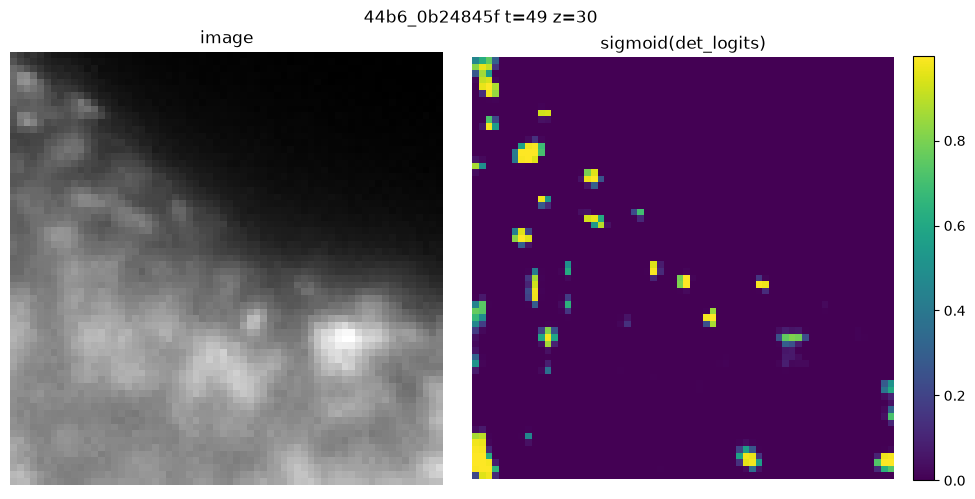

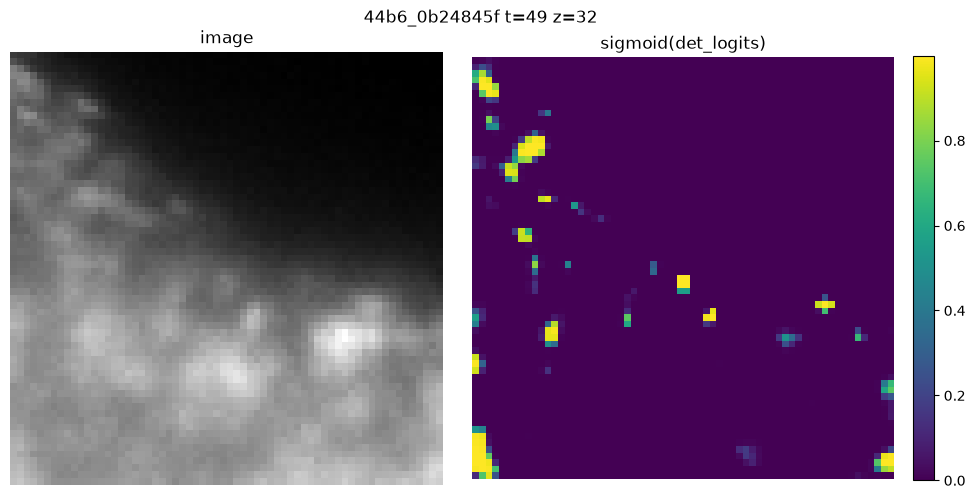

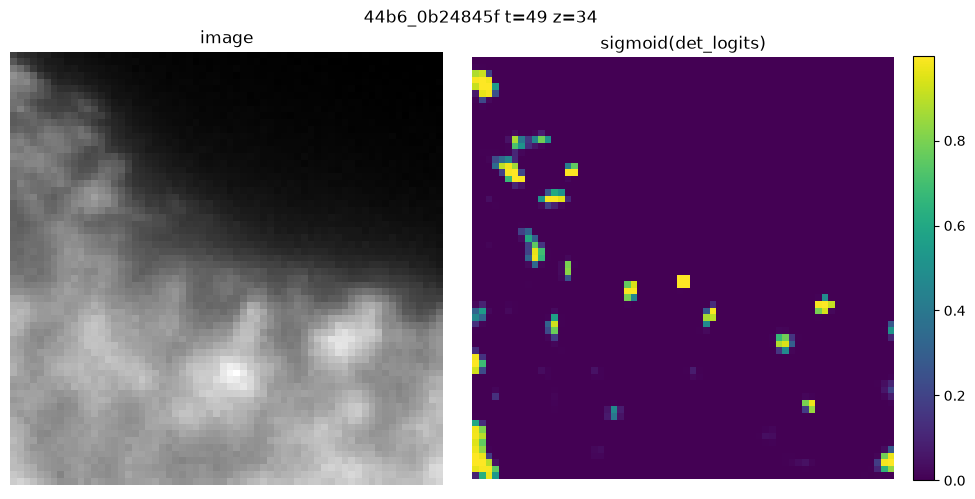

In [38]:
_viz_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
_viz_model, _viz_window_size, _viz_downsample = load_model(
    REPO_DIR / WEIGHTS_RELATIVE, _viz_device,
)

_viz_meta = json.loads((VIZ_DIR / f"{VIZ_DATASET}.zarr" / "0" / "zarr.json").read_text())
_viz_T = int(_viz_meta["shape"][0])
VIZ_T0 = max(0, _viz_T // 2 - _viz_window_size // 2)

viz_imgs, viz_logits = run_window_logits(
    _viz_model, VIZ_DIR / VIZ_DATASET, VIZ_T0,
    _viz_window_size, _viz_downsample, _viz_device, det_tta=True,
)
print(f"dataset={VIZ_DATASET} t0={VIZ_T0} window={_viz_window_size} "
      f"imgs={tuple(viz_imgs.shape)} logits={tuple(viz_logits[0].shape)}")

# The logits live on the downsampled grid, so z indexes that grid, not the raw volume.
_viz_mid_z = viz_logits[0].shape[0] // 2
for _dz in (-2, 0, 2):
    _z = max(0, min(viz_logits[0].shape[0] - 1, _viz_mid_z + _dz))
    plot_logits_slice(viz_imgs[0], viz_logits[0], _z,
                      title=f"{VIZ_DATASET} t={VIZ_T0} z={_z}")
    plt.show()


## Evaluate a Chosen Sample

Score one train video (which, unlike the test split, ships ground-truth
tracks) with the same official-spec metric the fixed-8 CV uses, then draw a
spatial error map for its worst frame.

This cell only needs the config cell above — it builds its own
`PostprocessConfig`, and predicts into its own `predictions/` subfolder
(`--method ..._eval_sample`) so it never clobbers the test-set graphs that
`submission.csv` is built from. The node-match result returned by
`official_spec_evaluate(..., return_match=True)` is reused for the plot
rather than recomputed.

In [39]:
TRAIN_DIR = COMP_DIR / "train"
if not TRAIN_DIR.exists():
    raise FileNotFoundError(f"Ground truth lives in the train split; not found: {TRAIN_DIR}")

# First train video carrying both an image and ground-truth tracks. Set
# EVAL_STEM by hand to score a different one.
EVAL_STEM = next(
    p.name[:-5] for p in sorted(TRAIN_DIR.iterdir())
    if p.name.endswith(".zarr") and (TRAIN_DIR / f"{p.name[:-5]}.geff").exists()
)
EVAL_METHOD = f"{METHOD}_eval_sample"   # own output dir, keeps test graphs intact
EVAL_FORCE_PREDICT = False              # True to re-run inference for this sample
EVAL_ZOOM_PX = 60                       # error-map half-width around the GT cells; None = whole frame

In [40]:
EVAL_STEM = "44b6_0b24845f"

In [41]:
_eval_geffs = sorted((REPO_DIR / "predictions").glob(f"*/{EVAL_METHOD}/split_0/{EVAL_STEM}.geff"))
if EVAL_FORCE_PREDICT or not _eval_geffs:
    _eval_cmd = [
        sys.executable, "scripts/predict_unet_transformer.py",
        "--debug-video",      str(TRAIN_DIR / EVAL_STEM),
        "--method",           EVAL_METHOD,
        "--weights",          WEIGHTS_RELATIVE,
        "--unet-batch-size",  str(UNET_BATCH_SIZE),
        "--det-threshold",    str(DET_THRESHOLD),
        "--ilp-edge-weight",  str(ILP_EDGE_WEIGHT),
        "--ilp-appearance-weight",    str(ILP_APPEARANCE_WEIGHT),
        "--ilp-disappearance-weight", str(ILP_DISAPPEARANCE_WEIGHT),
        "--ilp-division-weight",      str(ILP_DIVISION_WEIGHT),
    ]
    if USE_ILP:
        _eval_cmd.append("--use-ilp")
    print(" ".join(_eval_cmd))
    subprocess.run(_eval_cmd, cwd=REPO_DIR, env={**os.environ, "PYTHONPATH": "src"}, check=True)
    _eval_geffs = sorted((REPO_DIR / "predictions").glob(f"*/{EVAL_METHOD}/split_0/{EVAL_STEM}.geff"))
if not _eval_geffs:
    raise FileNotFoundError(f"No prediction graph produced for {EVAL_STEM}")

/data/kaggle-cell-tracking/.venv/bin/python scripts/predict_unet_transformer.py --debug-video /data/kaggle-cell-tracking/input/train/44b6_0b24845f --method unet_transformer_eval_sample --weights weights/unet_transformer/split_0/edge_predictor_best.pth --unet-batch-size 4 --det-threshold 0.96875 --ilp-edge-weight -1.0 --ilp-appearance-weight 0.0 --ilp-disappearance-weight 1.575 --ilp-division-weight 1.0 --use-ilp
Fold 0: 1 datasets | weights=weights/unet_transformer/split_0/edge_predictor_best.pth | device=cuda | window_size=2 | pool_kernel_um=3.0
Saved 1 predictions to /data/kaggle-cell-tracking/notebooks/clean-approach-lightweight-local-cv-no-hack/working/tracking_repo/predictions/root/unet_transformer_eval_sample/split_0


In [42]:
# Same post-processing the submission gets, so the score reflects the real pipeline.
EVAL_CFG = PostprocessConfig.from_notebook_globals(globals())
_eval_graph = graph_from_geff(_eval_geffs[0])
_eval_nodes = {
    int(r["node_id"]): {
        "node_id": int(r["node_id"]), "t": int(r["t"]),
        "z": float(r["z"]), "y": float(r["y"]), "x": float(r["x"]),
    }
    for r in _eval_graph.node_attrs().iter_rows(named=True)
}
_eval_raw_edges = [
    {
        "source_id": int(r["source_id"]), "target_id": int(r["target_id"]),
        "edge_prob": None if r.get("edge_prob") is None else float(r["edge_prob"]),
    }
    for r in _eval_graph.edge_attrs().iter_rows(named=True)
]
_eval_nodes, _eval_edges, _eval_stats = filter_output_graph(
    _eval_nodes, _eval_raw_edges, EVAL_CFG, TRAIN_DIR,
    dataset=EVAL_STEM, deepcenter_bundle=load_deepcenter_veto_detector(EVAL_CFG),
)

pred_nodes = pd.DataFrame(list(_eval_nodes.values()), columns=["node_id", "t", "z", "y", "x"])
pred_edges = pd.DataFrame(
    [{"source_id": e["source_id"], "target_id": e["target_id"]} for e in _eval_edges],
    columns=["source_id", "target_id"],
)
gt_nodes, gt_edges = _graph_tables(TRAIN_DIR / f"{EVAL_STEM}.geff", graph_from_geff)

eval_result, eval_match = official_spec_evaluate(
    pred_nodes, pred_edges, gt_nodes, gt_edges,
    scale=VOXEL_SCALE_UM, return_match=True,
)
eval_per_sample = official_spec_per_sample(
    eval_result, _estimated_total_nodes(TRAIN_DIR / f"{EVAL_STEM}.geff"),
)
display(pd.DataFrame([{
    "dataset": EVAL_STEM,
    "edge_tp": eval_result.edge_tp, "edge_fp": eval_result.edge_fp, "edge_fn": eval_result.edge_fn,
    "div_tp": eval_result.division_tp, "div_fp": eval_result.division_fp, "div_fn": eval_result.division_fn,
    "edge_jaccard": eval_per_sample["edge_jaccard"],
    "adj_edge_jaccard": eval_per_sample["adj_edge_jaccard"],
    "division_jaccard": eval_per_sample["division_jaccard"],
    "node_recall": eval_per_sample["node_recall"],
    "total_node_ratio": eval_per_sample["total_node_ratio"],
}]))


DeepCenter add-only repair gate disabled by configuration.


,dataset,edge_tp,edge_fp,edge_fn,div_tp,div_fp,div_fn,edge_jaccard,adj_edge_jaccard,division_jaccard,node_recall,total_node_ratio
0,44b6_0b24845f,49,0,0,0,0,0,1.0,1.038186,1.0,1.0,0.618143


In [43]:
# Ground truth is sparse — some videos annotate a single lineage — so rank
# frames by *missed annotations* (unmatched GT). Ranking by unmatched
# predictions instead would just pick the frame with the most cells in it,
# since unannotated cells are not errors.
_missed_per_t = {
    int(_t): sum(
        1 for i in gt_nodes.loc[gt_nodes["t"] == _t, "node_id"].astype(int)
        if i not in eval_match.gt_to_pred
    )
    for _t in sorted(set(gt_nodes["t"]))
}
_gt_per_frame = gt_nodes.groupby("t").size()
print(f"Ground truth: {len(gt_nodes)} nodes over {gt_nodes['t'].nunique()} frames "
      f"({_gt_per_frame.mean():.1f} annotated cells per frame) vs "
      f"{len(pred_nodes)} predicted nodes")

EVAL_ERROR_FRAME = max(_missed_per_t, key=_missed_per_t.get) if _missed_per_t else 0
print(f"Frame with most missed GT: t={EVAL_ERROR_FRAME} "
      f"({_missed_per_t.get(EVAL_ERROR_FRAME, 0)} missed of "
      f"{int(_gt_per_frame.get(EVAL_ERROR_FRAME, 0))} annotated)")



Ground truth: 51 nodes over 40 frames (1.3 annotated cells per frame) vs 20272 predicted nodes
Frame with most missed GT: t=11 (0 missed of 1 annotated)


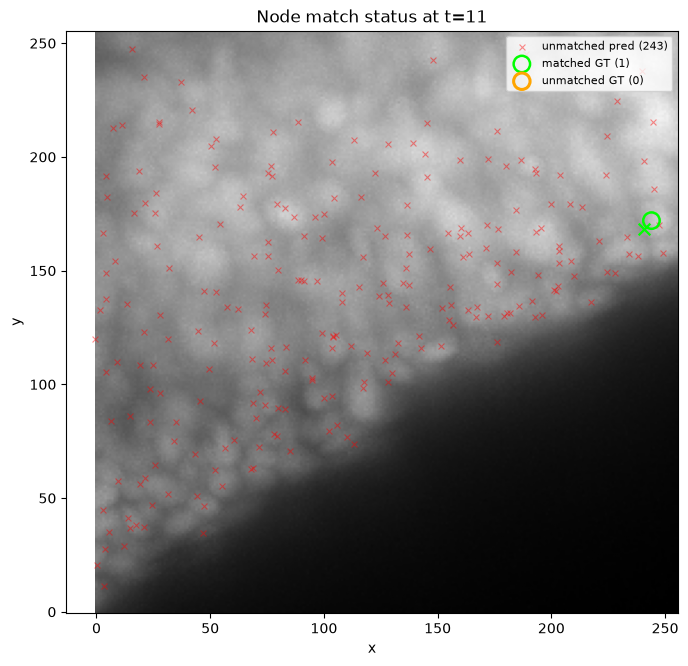

In [44]:
plot_sample_errors(
    pred_nodes,
    pred_edges,
    gt_nodes,
    gt_edges,
    eval_match,
    EVAL_ERROR_FRAME,
    VOXEL_SCALE_UM,
    img=read_test_frame(TRAIN_DIR, EVAL_STEM, EVAL_ERROR_FRAME, {}),
    # zoom_px=EVAL_ZOOM_PX,
)
plt.show()

## Submission output

After the Version completes, inspect the final Lite CV summary. Submit `submission.csv` only when the conservative rescue is activated and produces a positive paired LocalCV delta over the legitimate `0.908` clean baseline.
